In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
import warnings
warnings.filterwarnings('ignore')

In [ ]:
def convert_dat_to_csv(dat_file, csv_file, columns):
    df = pd.read_csv(dat_file, sep='::', header=None, names=columns, engine='python', encoding='latin-1')
    df.to_csv(csv_file, index=False)
    print(f"Converted {dat_file} to {csv_file}")

In [ ]:
ratings_columns = ['UserID', 'MovieID', 'Rating', 'Timestamp']
users_columns = ['UserID', 'Gender', 'Age', 'Occupation', 'Zip-code']
movies_columns = ['MovieID', 'Title', 'Genres']

In [ ]:
convert_dat_to_csv('ratings.dat', 'ratings.csv', ratings_columns)
convert_dat_to_csv('users.dat', 'users.csv', users_columns)
convert_dat_to_csv('movies.dat', 'movies.csv', movies_columns)

Converted ratings.dat to ratings.csv
Converted users.dat to users.csv
Converted movies.dat to movies.csv


In [ ]:
ratings = pd.read_csv('ratings.csv')
users = pd.read_csv('users.csv')
movies = pd.read_csv('movies.csv')

In [ ]:
ratings['Datetime'] = pd.to_datetime(ratings['Timestamp'], unit='s')
ratings['Year'] = ratings['Datetime'].dt.year
ratings['Month'] = ratings['Datetime'].dt.month
ratings['Weekday'] = ratings['Datetime'].dt.weekday

In [ ]:
print("\nRatings:")
print(ratings.info())
print("\nUsers :")
print(users.info())
print("\nMovies :")
print(movies.info())


Ratings:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 642001 entries, 0 to 642000
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   UserID     642001 non-null  object        
 1   MovieID    642000 non-null  float64       
 2   Rating     642000 non-null  float64       
 3   Timestamp  642000 non-null  float64       
 4   Datetime   642000 non-null  datetime64[ns]
 5   Year       642000 non-null  float64       
 6   Month      642000 non-null  float64       
 7   Weekday    642000 non-null  float64       
dtypes: datetime64[ns](1), float64(6), object(1)
memory usage: 39.2+ MB
None

Users :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6040 entries, 0 to 6039
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   UserID      6040 non-null   int64 
 1   Gender      6040 non-null   object
 2   Age         6040 non-null   int64 
 3   Occ

MERG

In [ ]:
# num_users = ratings['UserID'].nunique()
# num_movies = ratings['MovieID'].nunique()
# num_ratings = len(ratings)
# print(f"Number of users: {num_users}")
# print(f"Number of movies: {num_movies}")
# print(f"Number of ratings: {num_ratings}")

# Exploratory Data Analysis (EDA)

In [ ]:
ratings = pd.read_csv('ratings.csv')
movies = pd.read_csv('movies.csv')

In [ ]:
num_users = ratings['UserID'].nunique()
num_movies = ratings['MovieID'].nunique()
num_ratings = len(ratings)
print(f"Number of users: {num_users}")
print(f"Number of movies: {num_movies}")
print(f"Number of ratings: {num_ratings}")

Number of users: 3862
Number of movies: 3650
Number of ratings: 642001


In [ ]:
rating_stats = ratings['Rating'].describe()
print("\nRating distribution statistics:")
print(rating_stats)


Rating distribution statistics:
count    642000.000000
mean          3.572441
std           1.120663
min           1.000000
25%           3.000000
50%           4.000000
75%           4.000000
max           5.000000
Name: Rating, dtype: float64


 **Temporal Analysis Time**

In [ ]:
ratings['Timestamp'] = pd.to_datetime(ratings['Timestamp'], unit='s')
ratings['Year'] = ratings['Timestamp'].dt.year

**Ratings count per year**

In [ ]:
yearly_rating_counts = ratings['Year'].value_counts().sort_index()
print("\nNumber of ratings per year:")
print(yearly_rating_counts)


Number of ratings per year:
Year
2000.0    567440
2001.0     55076
2002.0     17615
2003.0      1869
Name: count, dtype: int64


**Average rating per year**

In [ ]:
yearly_avg_ratings = ratings.groupby('Year')['Rating'].mean()
print("\nAverage rating per year:")
print(yearly_avg_ratings)


Average rating per year:
Year
2000.0    3.584019
2001.0    3.507626
2002.0    3.423957
2003.0    3.366506
Name: Rating, dtype: float64


**User Activity Analysis**

In [ ]:
user_activity = ratings.groupby('UserID')['Rating'].count()
print("\nUser activity statistics:")
print(f"Average number of ratings per user: {user_activity.mean():.2f}")
print(f"Maximum ratings by a user: {user_activity.max()}")
print(f"Minimum ratings by a user: {user_activity.min()}")


User activity statistics:
Average number of ratings per user: 166.24
Maximum ratings by a user: 1850
Minimum ratings by a user: 0


Movie **Popularity**

In [ ]:
movie_popularity = ratings.groupby('MovieID')['Rating'].count()
print("\nMovie popularity statistics:")
print(f"Average number of ratings per movie: {movie_popularity.mean():.2f}")


Movie popularity statistics:
Average number of ratings per movie: 175.89


In [ ]:
rating_stats = ratings['Rating'].describe()
print("\nRating Distribution:")
print(f"Min Rating: {rating_stats['min']}")
print(f"Max Rating: {rating_stats['max']}")
print(f"Mean Rating: {rating_stats['mean']:.2f}")
print(f"Median Rating: {rating_stats['50%']}")


Rating Distribution:
Min Rating: 1.0
Max Rating: 5.0
Mean Rating: 3.57
Median Rating: 4.0


# Vizualizasion

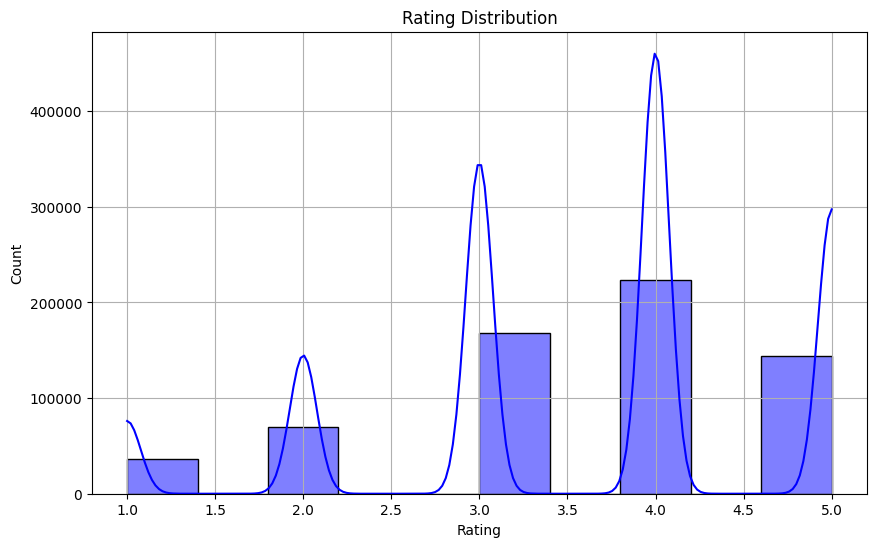

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(ratings['Rating'], bins=10, kde=True, color='blue')
plt.title('Rating Distribution')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.grid(True)
plt.show()

**Average Rating per Year**

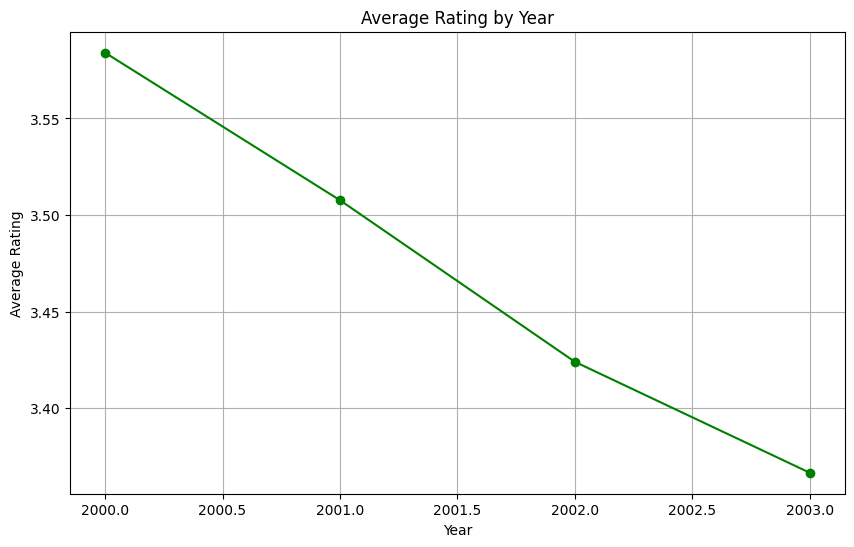

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(yearly_avg_ratings.index, yearly_avg_ratings.values, marker='o', color='green')
plt.title('Average Rating by Year')
plt.xlabel('Year')
plt.ylabel('Average Rating')
plt.grid(True)
plt.show()

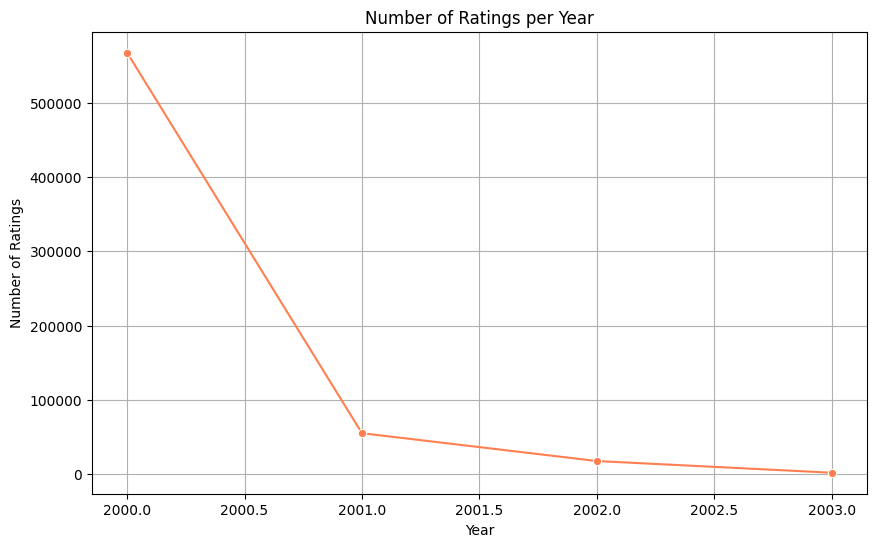

In [ ]:
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.lineplot(data=ratings.groupby('Year')['Rating'].count().reset_index(),
             x='Year', y='Rating', marker='o', color='coral')
plt.title('Number of Ratings per Year')
plt.xlabel('Year')
plt.ylabel('Number of Ratings')
plt.grid(True)
plt.show()


In [ ]:
print(ratings.columns)


Index(['UserID', 'MovieID', 'Rating', 'Timestamp', 'Year'], dtype='object')


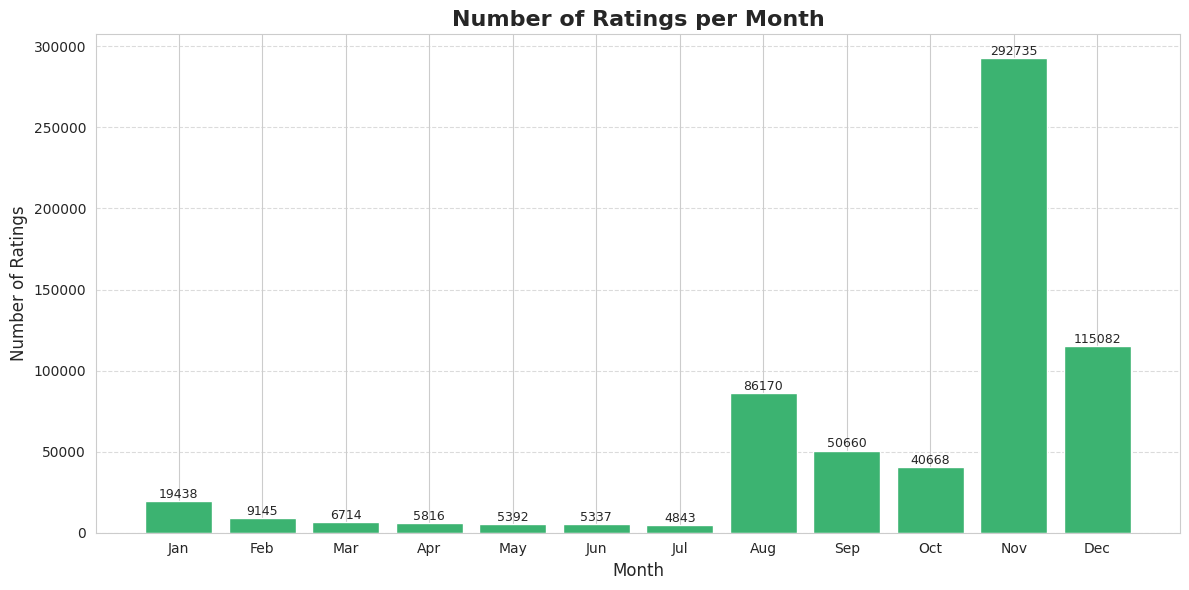

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

ratings['Timestamp'] = pd.to_datetime(ratings['Timestamp'], unit='s')

ratings['Month'] = ratings['Timestamp'].dt.month

month_counts = ratings.groupby('Month')['Rating'].count()

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
month_counts.index = [month_names[int(m) - 1] for m in month_counts.index]

plt.figure(figsize=(12, 6))
bars = plt.bar(month_counts.index, month_counts.values, color='mediumseagreen')

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 100, f'{height}',
             ha='center', va='bottom', fontsize=9)

plt.title('Number of Ratings per Month', fontsize=16, weight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Number of Ratings', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ratings['Timestamp'] = pd.to_datetime(ratings['Timestamp'], unit='s')

ratings['Weekday'] = ratings['Timestamp'].dt.weekday

weekday_counts = ratings.groupby('Weekday')['Rating'].count()

weekday_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
weekday_counts.index = [weekday_names[i] for i in weekday_counts.index]

sns.set_style("whitegrid")
plt.figure(figsize=(12, 6))
bars = plt.bar(weekday_counts.index, weekday_counts.values, color='cornflowerblue')

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 100, f'{height}',
             ha='center', va='bottom', fontsize=9)

plt.title('Number of Ratings per Weekday', fontsize=16, weight='bold')
plt.xlabel('Weekday', fontsize=12)
plt.ylabel('Number of Ratings', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


TypeError: list indices must be integers or slices, not float

# Average Rating by Year, Month, Weekday

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

yearly_avg = ratings.groupby('Year')['Rating'].mean().reset_index()

colors = sns.color_palette("Blues_r", len(yearly_avg))

plt.figure(figsize=(12, 6))
bars = plt.bar(yearly_avg['Year'], yearly_avg['Rating'], color=colors, width=0.5)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.05, f'{height:.2f}',
             ha='center', va='bottom', fontsize=10, color='black', fontweight='bold')

plt.title('Average Movie Ratings per Year', fontsize=18, fontweight='bold')
plt.xlabel('Year', fontsize=14)
plt.ylabel('Average Rating', fontsize=14)
plt.ylim(0, 5)
plt.xticks(rotation=45, ha='right', fontsize=11)  # Yil nomlarini biroz burish
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()

plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

ratings['Timestamp'] = pd.to_datetime(ratings['Timestamp'], unit='s')

ratings['Month'] = ratings['Timestamp'].dt.month

monthly_avg = ratings.groupby('Month')['Rating'].mean()

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_avg.index = [month_names[m-1] for m in monthly_avg.index]

plt.figure(figsize=(12, 6))

plt.plot(monthly_avg.index, monthly_avg.values, marker='o', color='mediumseagreen', linewidth=2)

for i, value in enumerate(monthly_avg.values):
    plt.text(monthly_avg.index[i], value + 0.05, f'{value:.2f}', ha='center', va='bottom', fontsize=9)

plt.title('Average Rating per Month', fontsize=16, weight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Average Rating', fontsize=12)
plt.grid(True, axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


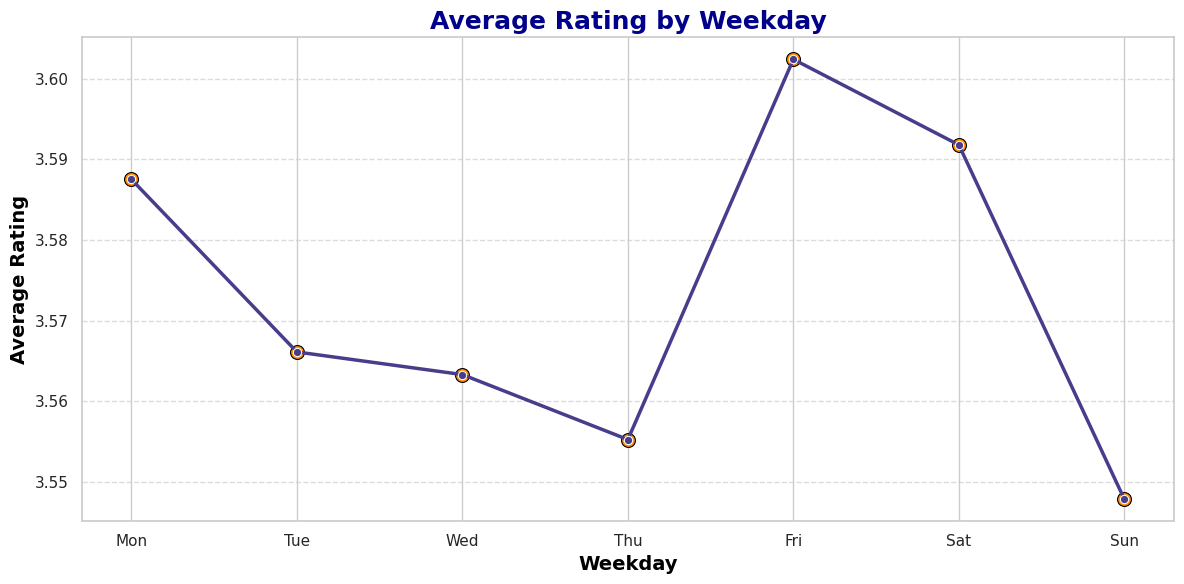

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid", palette="muted")

weekly_avg = ratings.groupby('Weekday')['Rating'].mean()

weekdays = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
weekly_avg.index = weekdays

plt.figure(figsize=(12, 6))

sns.lineplot(x=weekly_avg.index, y=weekly_avg.values, marker='o', color='darkslateblue', linewidth=2.5)

sns.scatterplot(x=weekly_avg.index, y=weekly_avg.values, color='darkorange', s=100, marker='o', edgecolor='black')

plt.title('Average Rating by Weekday', fontsize=18, weight='bold', color='darkblue')
plt.xlabel('Weekday', fontsize=14, weight='bold', color='black')
plt.ylabel('Average Rating', fontsize=14, weight='bold', color='black')

plt.grid(True, axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


**User Activity (Ratings per User)**

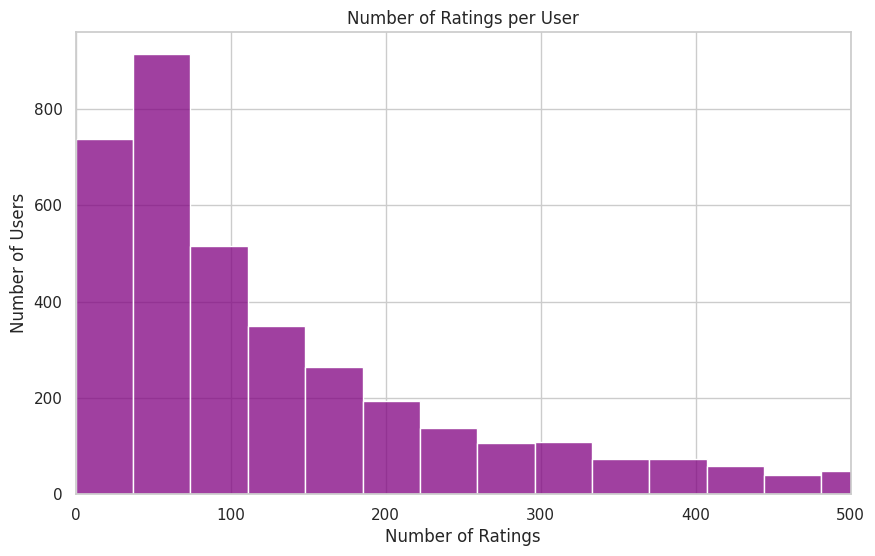

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(user_activity, bins=50, color='purple')
plt.title('Number of Ratings per User')
plt.xlabel('Number of Ratings')
plt.ylabel('Number of Users')
plt.xlim(0, 500)
plt.grid(True)
plt.show()

**Top 10 Most Rated Movies**

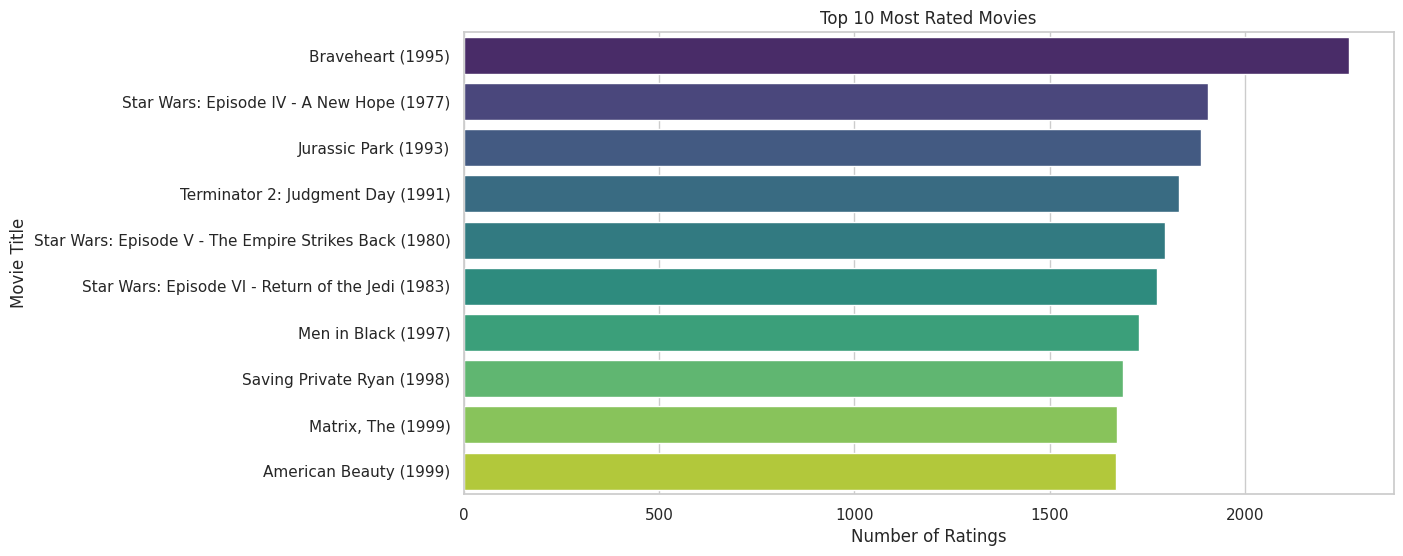

In [ ]:
top_movies = movie_popularity.sort_values(ascending=False).head(10)
top_movie_titles = movies[movies['MovieID'].isin(top_movies.index)].set_index('MovieID')['Title']
plt.figure(figsize=(12, 6))
sns.barplot(x=top_movies.values, y=top_movie_titles.values, palette='viridis')
plt.title('Top 10 Most Rated Movies')
plt.xlabel('Number of Ratings')
plt.ylabel('Movie Title')
plt.show()

**Average Rating vs Number of Ratings**

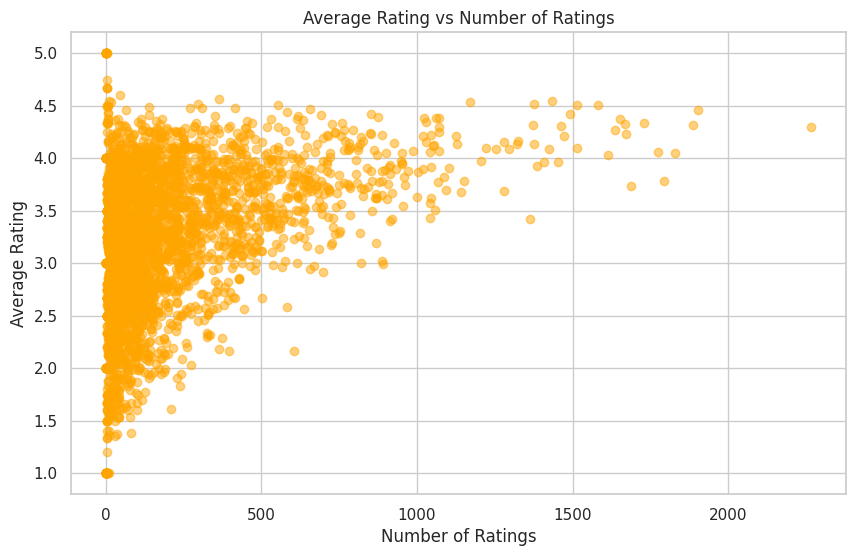

In [ ]:
movie_avg_rating = ratings.groupby('MovieID')['Rating'].mean()
movie_ratings_count = ratings.groupby('MovieID')['Rating'].count()
plt.figure(figsize=(10, 6))
plt.scatter(movie_ratings_count, movie_avg_rating, alpha=0.5, color='orange')
plt.title('Average Rating vs Number of Ratings')
plt.xlabel('Number of Ratings')
plt.ylabel('Average Rating')
plt.grid(True)
plt.show()

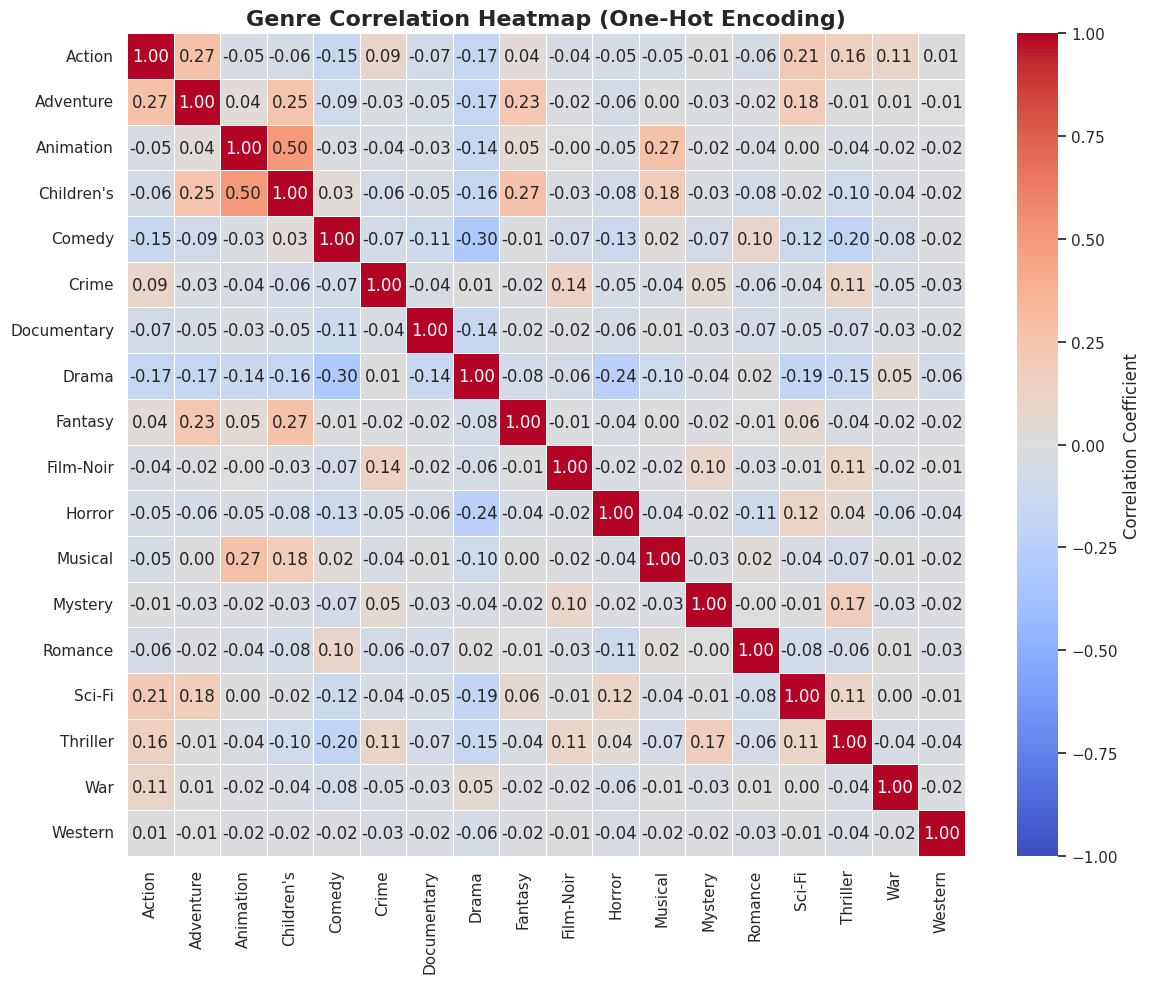

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Janrlarni one-hot encoding usulida kodlash
# 'Genres' ustunidagi har bir janr uchun yangi ustun yaratamiz
genre_matrix = movies['Genres'].str.get_dummies(sep='|')

# Korrelyatsiya matritsasini hisoblash
genre_correlation = genre_matrix.corr()

# Heatmap yaratish
plt.figure(figsize=(12, 10))
sns.heatmap(genre_correlation, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1,
            cbar_kws={'label': 'Correlation Coefficient'}, linewidths=0.5)

# Grafikni bezash
plt.title('Genre Correlation Heatmap (One-Hot Encoding)', fontsize=16, weight='bold')
plt.tight_layout()
plt.show()






> **Rating Distribution by Genre**






In [ ]:
movies['Genres'] = movies['Genres'].str.split('|')
genre_ratings = ratings.merge(movies[['MovieID', 'Genres']], on='MovieID')
genre_ratings = genre_ratings.explode('Genres')

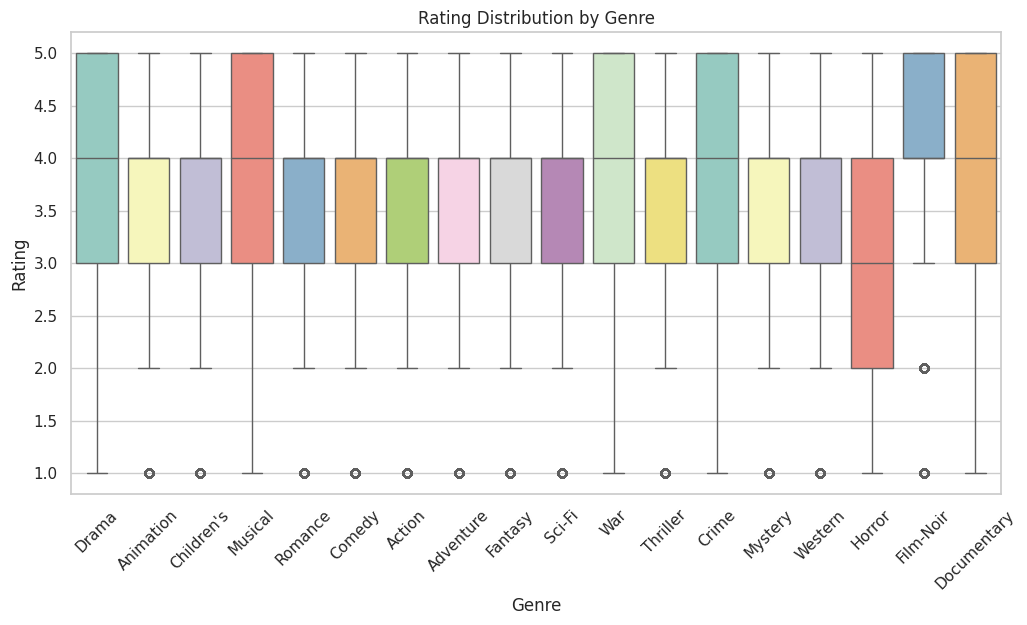

In [ ]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='Genres', y='Rating', data=genre_ratings, palette='Set3')
plt.title('Rating Distribution by Genre')
plt.xlabel('Genre')
plt.ylabel('Rating')
plt.xticks(rotation=45)
plt.show()

# Data Preprocessing

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [ ]:
ratings = pd.read_csv('ratings.csv')
movies = pd.read_csv('movies.csv')
users = pd.read_csv('users.csv')

**Merging**

In [ ]:
data = ratings.merge(users, on='UserID', how='left')
data = data.merge(movies, on='MovieID', how='left')


In [ ]:
print("\nMissing values:")
print(data.isnull().sum())


Missing values:
UserID               0
MovieID              0
Rating               0
Timestamp            0
Gender               0
Age                  0
Occupation           0
Zip-code             0
Title                0
Genres               0
Rating_normalized    0
Year                 0
Month                0
Day_of_week          0
Hour                 0
Gender_encoded       0
Age_group            0
Action               0
Adventure            0
Animation            0
Children's           0
Comedy               0
Crime                0
Documentary          0
Drama                0
Fantasy              0
Film-Noir            0
Horror               0
Musical              0
Mystery              0
Romance              0
Sci-Fi               0
Thriller             0
War                  0
Western              0
Datetime             0
dtype: int64


In [ ]:
data['Genres'] = data['Genres'].fillna('Unknown')
data['Title'] = data['Title'].fillna('Unknown')
data['Gender'] = data['Gender'].fillna('Unknown')
data['Age'] = data['Age'].fillna(data['Age'].median())
data['Occupation'] = data['Occupation'].fillna('Unknown')
data['Zip-code'] = data['Zip-code'].fillna('Unknown')

In [ ]:
print("\nMissing values after cleaning:")
print(data.isnull().sum())


Missing values after cleaning:
UserID               0
MovieID              0
Rating               0
Timestamp            0
Gender               0
Age                  0
Occupation           0
Zip-code             0
Title                0
Genres               0
Rating_normalized    0
Year                 0
Month                0
Day_of_week          0
Hour                 0
Gender_encoded       0
Age_group            0
Action               0
Adventure            0
Animation            0
Children's           0
Comedy               0
Crime                0
Documentary          0
Drama                0
Fantasy              0
Film-Noir            0
Horror               0
Musical              0
Mystery              0
Romance              0
Sci-Fi               0
Thriller             0
War                  0
Western              0
Datetime             0
dtype: int64


In [ ]:
data = data[(data['Rating'] >= 0.5) & (data['Rating'] <= 5)]
print(f"\nDataset size after outlier removal: {len(data)}")


Dataset size after outlier removal: 642000




>**Normalize ratings**



In [ ]:
scaler = StandardScaler()
data['Rating_normalized'] = scaler.fit_transform(data[['Rating']])
print("\nSample normalized ratings:")
print(data[['Rating', 'Rating_normalized']].head())


Sample normalized ratings:
   Rating  Rating_normalized
0     5.0           1.273854
1     3.0          -0.510806
2     3.0          -0.510806
3     4.0           0.381524
4     5.0           1.273854


# ***Feature Engineering***



In [ ]:
data['Timestamp'] = pd.to_datetime(data['Timestamp'], unit='s')
data['Year'] = data['Timestamp'].dt.year
data['Month'] = data['Timestamp'].dt.month
data['Day_of_week'] = data['Timestamp'].dt.dayofweek
data['Hour'] = data['Timestamp'].dt.hour



In [ ]:
data['Timestamp'] = pd.to_datetime(data['Timestamp'], unit='s')
data['Year'] = data['Timestamp'].dt.year
print("\nYear feature:")
print(data[['UserID', 'MovieID', 'Rating', 'Timestamp', 'Year']].head())


Year feature:
  UserID  MovieID  Rating           Timestamp  Year
0      1   1193.0     5.0 2000-12-31 22:12:40  2000
1      1    661.0     3.0 2000-12-31 22:35:09  2000
2      1    914.0     3.0 2000-12-31 22:32:48  2000
3      1   3408.0     4.0 2000-12-31 22:04:35  2000
4      1   2355.0     5.0 2001-01-06 23:38:11  2001




> **Gender encoding**


In [ ]:
data['Gender_encoded'] = data['Gender'].map({'M': 1, 'F': 0, 'Unknown': -1})
print("\nGender encoding:")
print(data[['UserID', 'Gender', 'Gender_encoded']].head())



Gender encoding:
  UserID Gender  Gender_encoded
0      1      F               0
1      1      F               0
2      1      F               0
3      1      F               0
4      1      F               0


In [ ]:
# Encode Age into groups
age_bins = [0, 18, 25, 35, 45, 55, 100]
age_labels = ['0-18', '19-25', '26-35', '36-45', '46-55', '56+']
data['Age_group'] = pd.cut(data['Age'], bins=age_bins, labels=age_labels, include_lowest=True)
print("\nAge group encoding:")
print(data[['UserID', 'Age', 'Age_group']].head())


Age group encoding:
  UserID  Age Age_group
0      1  1.0      0-18
1      1  1.0      0-18
2      1  1.0      0-18
3      1  1.0      0-18
4      1  1.0      0-18




> **One-hot encode Genres**



In [ ]:
movies['Genres'] = movies['Genres'].astype(str).str.split('|')
genre_data = movies[['MovieID', 'Genres']].explode('Genres')
genre_dummies = pd.get_dummies(genre_data['Genres']).groupby(genre_data['MovieID']).sum()
data = data.merge(genre_dummies, on='MovieID', how='left')
data[genre_dummies.columns] = data[genre_dummies.columns].fillna(0)

In [ ]:
data['Datetime'] = pd.to_datetime(ratings['Timestamp'], unit='s').astype(int) / 10**9

In [ ]:
data

,UserID,MovieID,Rating,Timestamp,Gender,Age,Occupation,Zip-code,Title,Genres,...,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,Datetime,nan
0,1,1193.0,5.0,2000-12-31 22:12:40,F,1.0,10.0,48067,One Flew Over the Cuckoo's Nest (1975),Drama,...,0,0,0,0,0,0,0,0,978300760.0,1
1,1,661.0,3.0,2000-12-31 22:35:09,F,1.0,10.0,48067,James and the Giant Peach (1996),Animation|Children's|Musical,...,0,1,0,0,0,0,0,0,978302109.0,1
2,1,914.0,3.0,2000-12-31 22:32:48,F,1.0,10.0,48067,My Fair Lady (1964),Musical|Romance,...,0,1,0,1,0,0,0,0,978301968.0,1
3,1,3408.0,4.0,2000-12-31 22:04:35,F,1.0,10.0,48067,Erin Brockovich (2000),Drama,...,0,0,0,0,0,0,0,0,978300275.0,1
4,1,2355.0,5.0,2001-01-06 23:38:11,F,1.0,10.0,48067,"Bug's Life, A (1998)",Animation|Children's|Comedy,...,0,0,0,0,0,0,0,0,978824291.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
641995,3860,2402.0,5.0,2000-08-09 22:43:16,Unknown,25.0,Unknown,Unknown,Rambo: First Blood Part II (1985),Action|War,...,0,0,0,0,0,0,1,0,965860996.0,1
641996,3860,2404.0,4.0,2000-08-09 22:43:48,Unknown,25.0,Unknown,Unknown,Rambo III (1988),Action|War,...,0,0,0,0,0,0,1,0,965861028.0,1
641997,3860,3062.0,4.0,2000-08-09 22:40:08,Unknown,25.0,Unknown,Unknown,"Longest Day, The (1962)",Action|Drama|War,...,0,0,0,0,0,0,1,0,965860808.0,1
641998,3860,2407.0,4.0,2000-08-09 22:36:22,Unknown,25.0,Unknown,Unknown,Cocoon (1985),Comedy|Sci-Fi,...,0,0,0,0,1,0,0,0,965860582.0,1


User-movie interaction features

># Number of ratings per user



In [ ]:
if 'User_rating_count' in data.columns:
    data = data.drop(columns='User_rating_count')
user_rating_count = data.groupby('UserID')['Rating'].count().rename('User_rating_count')
data = data.merge(user_rating_count, on='UserID', how='left')
print("\nOne-hot encoding Genres:")
print(data[['MovieID'] + list(genre_dummies.columns)].head())


One-hot encoding Genres:
   MovieID  Action  Adventure  Animation  Children's  Comedy  Crime  \
0     1193       0          0          0           0       0      0   
1      661       0          0          1           1       0      0   
2      914       0          0          0           0       0      0   
3     3408       0          0          0           0       0      0   
4     2355       0          0          1           1       1      0   

   Documentary  Drama  Fantasy  Film-Noir  Horror  Musical  Mystery  Romance  \
0            0      1        0          0       0        0        0        0   
1            0      0        0          0       0        1        0        0   
2            0      0        0          0       0        1        0        1   
3            0      1        0          0       0        0        0        0   
4            0      0        0          0       0        0        0        0   

   Sci-Fi  Thriller  War  Western  
0       0         0    0      

4. User-movie interaction features

# Number of ratings per user

In [ ]:
if 'User_rating_count' in data.columns:
    data = data.drop(columns='User_rating_count')
user_rating_count = data.groupby('UserID')['Rating'].count().rename('User_rating_count')
data = data.merge(user_rating_count, on='UserID', how='left')

print("\nUser rating count:")
print(data[['UserID', 'User_rating_count']].head())


User rating count:
   UserID  User_rating_count
0       1                 53
1       1                 53
2       1                 53
3       1                 53
4       1                 53


In [ ]:
print("\nSample of engineered features:")
print(data[['UserID', 'MovieID', 'Rating', 'Year', 'Gender_encoded', 'User_rating_count']].head())



Sample of engineered features:
   UserID  MovieID  Rating  Year  Gender_encoded  User_rating_count
0       1     1193       5  2000               0                 53
1       1      661       3  2000               0                 53
2       1      914       3  2000               0                 53
3       1     3408       4  2000               0                 53
4       1     2355       5  2001               0                 53


Number of ratings per movie

In [ ]:
if 'Movie_rating_count' in data.columns:
    data = data.drop(columns='Movie_rating_count')
movie_rating_count = data.groupby('MovieID')['Rating'].count().rename('Movie_rating_count')
data = data.merge(movie_rating_count, on='MovieID', how='left')

print("\nMovie rating count:")
print(data[['MovieID', 'Movie_rating_count']].head())


Movie rating count:
   MovieID  Movie_rating_count
0     1193                1725
1      661                 525
2      914                 636
3     3408                1315
4     2355                1703


In [ ]:
# Average rating per user
if 'User_avg_rating' in data.columns:
    data = data.drop(columns='User_avg_rating')
user_avg_rating = data.groupby('UserID')['Rating'].mean().rename('User_avg_rating')
data = data.merge(user_avg_rating, on='UserID', how='left')

print("\nUser average rating:")
print(data[['UserID', 'User_avg_rating']].head())


User average rating:
   UserID  User_avg_rating
0       1         4.188679
1       1         4.188679
2       1         4.188679
3       1         4.188679
4       1         4.188679


In [ ]:
print("\n User-Movie Interaction Feature: Movie Rating Count ===")
if 'Movie_rating_count' in data.columns:
    print("\n'Movie_rating_count' column already exists. Dropping it to avoid conflicts.")
    data = data.drop(columns='Movie_rating_count')

movie_rating_count = data.groupby('MovieID')['Rating'].count().rename('Movie_rating_count')

data = data.merge(movie_rating_count, on='MovieID', how='left')

print("\nSample with Movie_rating_count feature:")
print(data[['UserID', 'MovieID', 'Rating', 'Movie_rating_count']].head())


 User-Movie Interaction Feature: Movie Rating Count ===

'Movie_rating_count' column already exists. Dropping it to avoid conflicts.

Sample with Movie_rating_count feature:
   UserID  MovieID  Rating  Movie_rating_count
0       1     1193       5                1725
1       1      661       3                 525
2       1      914       3                 636
3       1     3408       4                1315
4       1     2355       5                1703


**New Temporal Movie Feature**

In [ ]:

print("\n===  Movie Rating Count by Year ===")

movie_rating_count_by_year = data.groupby(['MovieID', 'Year'])['Rating'].count().unstack().fillna(0)

movie_rating_count_by_year.columns = [f'Rating_count_{year}' for year in movie_rating_count_by_year.columns]


data = data.merge(movie_rating_count_by_year, on='MovieID', how='left')
data[movie_rating_count_by_year.columns] = data[movie_rating_count_by_year.columns].fillna(0)
year_cols = movie_rating_count_by_year.columns.tolist()
print("\nSample with Movie_rating_count_by_year features:")
print(data[['MovieID', 'Title', 'Year'] + year_cols[:3]].head())


===  Movie Rating Count by Year ===

Sample with Movie_rating_count_by_year features:
   MovieID                                   Title  Year  Rating_count_2000  \
0     1193  One Flew Over the Cuckoo's Nest (1975)  2000             1622.0   
1      661        James and the Giant Peach (1996)  2000              480.0   
2      914                     My Fair Lady (1964)  2000              566.0   
3     3408                  Erin Brockovich (2000)  2000             1087.0   
4     2355                    Bug's Life, A (1998)  2001             1586.0   

   Rating_count_2001  Rating_count_2002  
0               73.0               28.0  
1               37.0                6.0  
2               51.0               17.0  
3              179.0               43.0  
4               82.0               28.0  


Movie Rating Count by **Month**

In [ ]:

data['Year_Month'] = data['Timestamp'].dt.to_period('M')
movie_rating_count_by_month = data.groupby(['MovieID', 'Year_Month'])['Rating'].count().unstack().fillna(0)
movie_rating_count_by_month.columns = [f'Rating_count_{month}' for month in movie_rating_count_by_month.columns]

data = data.merge(movie_rating_count_by_month, on='MovieID', how='left')
data[movie_rating_count_by_month.columns] = data[movie_rating_count_by_month.columns].fillna(0)

month_cols = movie_rating_count_by_month.columns.tolist()
print("\nSample with Movie_rating_count_by_month features:")
print(data[['MovieID', 'Title', 'Year_Month'] + month_cols[:3]].head())




Sample with Movie_rating_count_by_month features:
   MovieID                                   Title Year_Month  \
0     1193  One Flew Over the Cuckoo's Nest (1975)    2000-12   
1      661        James and the Giant Peach (1996)    2000-12   
2      914                     My Fair Lady (1964)    2000-12   
3     3408                  Erin Brockovich (2000)    2000-12   
4     2355                    Bug's Life, A (1998)    2001-01   

   Rating_count_2000-04  Rating_count_2000-05  Rating_count_2000-06  
0                  25.0                 132.0                 110.0  
1                   6.0                  23.0                  33.0  
2                   9.0                  53.0                  33.0  
3                  14.0                  67.0                  57.0  
4                  21.0                 130.0                 109.0  


# **Dataset Splitting**

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

**train (70%) and temp (30%)**

In [ ]:
print("\n=== 1. Standard Split: Randomly Shuffling for Fairness ===")

train, temp = train_test_split(ratings, test_size=0.3, random_state=42)

validation, test = train_test_split(temp, test_size=0.5, random_state=42)

print("\nStandard split sizes:")
print(f"Train set: {len(train)} rows")
print(f"Validation set: {len(validation)} rows")
print(f"Test set: {len(test)} rows")

print("\nTrain set:")
print(train[['UserID', 'MovieID', 'Rating']].head())
print("\nValidation set :")
print(validation[['UserID', 'MovieID', 'Rating']].head())
print("\nTest set :")
print(test[['UserID', 'MovieID', 'Rating']].head())


=== 1. Standard Split: Randomly Shuffling for Fairness ===

Standard split sizes:
Train set: 700146 rows
Validation set: 150031 rows
Test set: 150032 rows

Train set:
        UserID  MovieID  Rating
539061    3314     2787       2
6514        48      647       3
623156    3770     1079       4
77441      524     1126       1
559047    3434     2470       3

Validation set :
        UserID  MovieID  Rating
197102    1209     3769       2
435911    2664      150       4
329609    1943     3596       1
526110    3252     2987       3
86073      563      405       1

Test set :
        UserID  MovieID  Rating
212834    1297      253       3
949380    5736      608       5
52157      343      153       4
884935    5345     2406       5
790791    4728     1393       4


In [ ]:
ratings_sorted = ratings.sort_values('Timestamp')
#  70%/15%/15%
train_size = int(0.7 * len(ratings))
val_size = int(0.15 * len(ratings))

train_temporal = ratings_sorted.iloc[:train_size]
validation_temporal = ratings_sorted.iloc[train_size:train_size + val_size]
test_temporal = ratings_sorted.iloc[train_size + val_size:]

print("\nTemporal split sizes:")
print(f"Temporal Train set: {len(train_temporal)} rows")
print(f"Temporal Validation set: {len(validation_temporal)} rows")
print(f"Temporal Test set: {len(test_temporal)} rows")

print("\nTemporal Train set sample:")
print(train_temporal[['UserID', 'MovieID', 'Rating', 'Timestamp']].head())
print("\nTemporal Validation set sample:")
print(validation_temporal[['UserID', 'MovieID', 'Rating', 'Timestamp']].head())
print("\nTemporal Test set sample:")
print(test_temporal[['UserID', 'MovieID', 'Rating', 'Timestamp']].head())


Temporal split sizes:
Temporal Train set: 700146 rows
Temporal Validation set: 150031 rows
Temporal Test set: 150032 rows

Temporal Train set sample:
         UserID  MovieID  Rating  Timestamp
1000138    6040      858       4  956703932
1000153    6040     2384       4  956703954
999873     6040      593       5  956703954
1000007    6040     1961       4  956703977
1000192    6040     2019       5  956703977

Temporal Validation set sample:
        UserID  MovieID  Rating  Timestamp
187235    1162      919       3  974862386
187266    1162     3435       4  974862386
187409    1163     1754       3  974862390
187420    1163       44       4  974862390
187418    1163     1792       3  974862390

Temporal Test set sample:
        UserID  MovieID  Rating  Timestamp
48360      326     1263       2  976422054
48364      326     1193       3  976422054
48632      326      515       3  976422083
323378    1917     1287       5  976422083
48562      326     3471       4  976422083


In [ ]:
user_movie_matrix = train.pivot_table(index='UserID', columns='MovieID', values='Rating').fillna(0)

print("\nUser-Movie Matrix size:")
print(f"Shape: {user_movie_matrix.shape} (rows=users, columns=movies)")
print("\nSample of User-Movie Matrix (first 5 users, first 5 movies):")
print(user_movie_matrix.iloc[:5, :5])


train.to_csv('train_data.csv', index=False)
validation.to_csv('validation_data.csv', index=False)
test.to_csv('test_data.csv', index=False)
train_temporal.to_csv('train_temporal_data.csv', index=False)
validation_temporal.to_csv('validation_temporal_data.csv', index=False)
test_temporal.to_csv('test_temporal_data.csv', index=False)
user_movie_matrix.to_csv('user_movie_matrix.csv')
print("\nAll datasets and matrix saved as CSV files. Ready for modeling!")


User-Movie Matrix size:
Shape: (6040, 3664) (rows=users, columns=movies)

Sample of User-Movie Matrix (first 5 users, first 5 movies):
MovieID    1    2    3    4    5
UserID                          
1        5.0  0.0  0.0  0.0  0.0
2        0.0  0.0  0.0  0.0  0.0
3        0.0  0.0  0.0  0.0  0.0
4        0.0  0.0  0.0  0.0  0.0
5        0.0  0.0  0.0  0.0  0.0

All datasets and matrix saved as CSV files. Ready for modeling!


# Model Development and Training Code

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error



In [ ]:
!pip uninstall -y numpy scikit-surprise
!pip install numpy==1.23.5
!pip install scikit-surprise

import numpy as np
print(f"NumPy versiyasi: {np.__version__}")
X_train = train[['UserID', 'MovieID']]
y_train = train['Rating']
X_val = validation[['UserID', 'MovieID']]
y_val = validation['Rating']

print("Surprise ichki modullari muvaffaqiyatli import qilindi!")

Found existing installation: numpy 1.23.5
Uninstalling numpy-1.23.5:
  Successfully uninstalled numpy-1.23.5
Found existing installation: scikit-surprise 1.1.4
Uninstalling scikit-surprise-1.1.4:
  Successfully uninstalled scikit-surprise-1.1.4
  Using cached numpy-1.23.5-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (2.3 kB)
Using cached numpy-1.23.5-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (17.1 MB)
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
thinc 8.3.6 requires numpy<3.0.0,>=2.0.0, but you have numpy 1.23.5 which is incompatible.
chex 0.1.89 requires numpy>=1.24.1, but you have numpy 1.23.5 which is incompatible.
xarray 2025.1.2 requires numpy>=1.24, but you have numpy 1.23.5 which is incompatible.
bigframes 1.42.0 requires numpy>=1.24.0, but you have numpy 1.23.5 which is incompatible.
albumentations 2.0.5 requir

  Using cached scikit_surprise-1.1.4-cp311-cp311-linux_x86_64.whl


NumPy versiyasi: 1.23.5
Surprise ichki modullari muvaffaqiyatli import qilindi!


In [ ]:
!pip uninstall -y scikit-surprise
!pip install scikit-surprise

import numpy as np
print(f"NumPy versiyasi: {np.__version__}")
# import surprise

# print(f"Surprise versiyasi: {surprise.__version__}")

Found existing installation: scikit-surprise 1.1.4
Uninstalling scikit-surprise-1.1.4:
  Successfully uninstalled scikit-surprise-1.1.4
  Using cached scikit_surprise-1.1.4-cp311-cp311-linux_x86_64.whl


NumPy versiyasi: 1.23.5
Surprise versiyasi: 1.1.4


In [ ]:
!pip install seaborn


In [ ]:
import seaborn as sns
sns.set(style='whitegrid')  # Use Seaborn's whitegrid style
sns.set_palette('muted')

In [ ]:
train_temporal = pd.read_csv('train_temporal_data.csv')
validation_temporal = pd.read_csv('validation_temporal_data.csv')
test_temporal = pd.read_csv('test_temporal_data.csv')
user_movie_matrix = pd.read_csv('user_movie_matrix.csv', index_col=0)
print("\nTemporal split sizes:")
print(f"Temporal Train set: {len(train_temporal)} rows")
print(f"Temporal Validation set: {len(validation_temporal)} rows")
print(f"Temporal Test set: {len(test_temporal)} rows")


Temporal split sizes:
Temporal Train set: 700146 rows
Temporal Validation set: 150031 rows
Temporal Test set: 150032 rows


In [ ]:
print("\nTemporal Train set sample:")
print(train_temporal[['UserID', 'MovieID', 'Rating', 'Timestamp']].head())
print("\nTemporal Validation set sample:")
print(validation_temporal[['UserID', 'MovieID', 'Rating', 'Timestamp']].head())
print("\nTemporal Test set sample:")
print(test_temporal[['UserID', 'MovieID', 'Rating', 'Timestamp']].head())

# Print user-movie matrix details
print("\nUser-Movie Matrix size:")
print(f"Shape: {user_movie_matrix.shape} (rows=users, columns=movies)")
print("\nSample of User-Movie Matrix (first 5 users, first 5 movies):")
print(user_movie_matrix.iloc[:5, :5])


Temporal Train set sample:
   UserID  MovieID  Rating  Timestamp
0    6040      858       4  956703932
1    6040     2384       4  956703954
2    6040      593       5  956703954
3    6040     1961       4  956703977
4    6040     2019       5  956703977

Temporal Validation set sample:
   UserID  MovieID  Rating  Timestamp
0    1162      919       3  974862386
1    1162     3435       4  974862386
2    1163     1754       3  974862390
3    1163       44       4  974862390
4    1163     1792       3  974862390

Temporal Test set sample:
   UserID  MovieID  Rating  Timestamp
0     326     1263       2  976422054
1     326     1193       3  976422054
2     326      515       3  976422083
3    1917     1287       5  976422083
4     326     3471       4  976422083

User-Movie Matrix size:
Shape: (6040, 3664) (rows=users, columns=movies)

Sample of User-Movie Matrix (first 5 users, first 5 movies):
          1    2    3    4    5
UserID                         
1       5.0  0.0  0.0  0.0  

In [ ]:
X_train = train_temporal[['UserID', 'MovieID']]
y_train = train_temporal['Rating']
X_val = validation_temporal[['UserID', 'MovieID']]
y_val = validation_temporal['Rating']


**Supervised Learning: KNN**

In [ ]:
knn = KNeighborsRegressor(n_neighbors=5, metric='cosine')
knn.fit(X_train, y_train)
knn_preds = knn.predict(X_val)
knn_rmse = np.sqrt(mean_squared_error(y_val, knn_preds))
knn_mae = mean_absolute_error(y_val, knn_preds)
print("\nKNN results:")
print(f"RMSE: {knn_rmse:.4f}")
print(f"MAE: {knn_mae:.4f}")
print("\n KNN predictions:")
print(pd.DataFrame({'Actual': y_val[:5].values, 'Predicted': knn_preds[:5]}))


KNN results:
RMSE: 1.2615
MAE: 1.0071

 KNN predictions:
   Actual  Predicted
0       3        3.8
1       4        2.8
2       3        4.0
3       4        3.6
4       3        4.0


Supervised Learning: Decision Tree

In [ ]:
dt = DecisionTreeRegressor(max_depth=10, random_state=42)
dt.fit(X_train, y_train)
dt_preds = dt.predict(X_val)
dt_rmse = np.sqrt(mean_squared_error(y_val, dt_preds))
dt_mae = mean_absolute_error(y_val, dt_preds)
print("\nDecision Tree results:")
print(f"RMSE: {dt_rmse:.4f}")
print(f"MAE: {dt_mae:.4f}")
print("\n Decision Tree predictions:")
print(pd.DataFrame({'Actual': y_val[:5].values, 'Predicted': dt_preds[:5]}))


Decision Tree results:
RMSE: 1.0713
MAE: 0.8666

 Decision Tree predictions:
   Actual  Predicted
0       3   4.160819
1       4   3.584972
2       3   3.040770
3       4   3.673659
4       3   3.334045


**Random Forest**

In [ ]:
rf = RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_preds = rf.predict(X_val)
rf_rmse = np.sqrt(mean_squared_error(y_val, rf_preds))
rf_mae = mean_absolute_error(y_val, rf_preds)
print("\nRandom Forest results:")
print(f"RMSE: {rf_rmse:.4f}")
print(f"MAE: {rf_mae:.4f}")
print("\n Random Forest predictions:")
print(pd.DataFrame({'Actual': y_val[:5].values, 'Predicted': rf_preds[:5]}))


Random Forest results:
RMSE: 1.0500
MAE: 0.8539

 Random Forest predictions:
   Actual  Predicted
0       3   4.177636
1       4   3.585043
2       3   3.133002
3       4   3.647428
4       3   3.325635


** XGBoost**

In [ ]:
!pip install xgboost


In [ ]:
from xgboost import XGBRegressor
xgb = XGBRegressor(n_estimators=50, max_depth=5, learning_rate=0.1, random_state=42, n_jobs=-1)
xgb.fit(X_train, y_train)
xgb_preds = xgb.predict(X_val)
xgb_rmse = np.sqrt(mean_squared_error(y_val, xgb_preds))
xgb_mae = mean_absolute_error(y_val, xgb_preds)
print("\nXGBoost results:")
print(f"RMSE: {xgb_rmse:.4f}")
print(f"MAE: {xgb_mae:.4f}")
print("\n XGBoost predictions:")
print(pd.DataFrame({'Actual': y_val[:5].values, 'Predicted': xgb_preds[:5]}))


XGBoost results:
RMSE: 1.0896
MAE: 0.8951

 XGBoost predictions:
   Actual  Predicted
0       3   4.140222
1       4   3.465998
2       3   3.460284
3       4   3.691550
4       3   3.440612



> **Collaborative Filtering: SVD**







In [ ]:
!pip uninstall -y scikit-surprise numpy
!pip install numpy
!pip install scikit-surprise

Found existing installation: scikit-surprise 1.1.4
Uninstalling scikit-surprise-1.1.4:
  Successfully uninstalled scikit-surprise-1.1.4
Found existing installation: numpy 1.23.5
Uninstalling numpy-1.23.5:
  Successfully uninstalled numpy-1.23.5
  Using cached numpy-2.2.5-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (62 kB)
Using cached numpy-2.2.5-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (16.4 MB)
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have numpy 2.2.5 which is incompatible.
tensorflow 2.18.0 requires numpy<2.1.0,>=1.26.0, but you have numpy 2.2.5 which is incompatible.
  Using cached scikit_surprise-1.1.4-cp311-cp311-linux_x86_64.whl


In [ ]:
!pip uninstall -y numpy scikit-surprise
!pip install numpy==1.23.5
!pip install scikit-surprise

Found existing installation: numpy 2.2.5
Uninstalling numpy-2.2.5:
  Successfully uninstalled numpy-2.2.5
Found existing installation: scikit-surprise 1.1.4
Uninstalling scikit-surprise-1.1.4:
  Successfully uninstalled scikit-surprise-1.1.4
  Using cached numpy-1.23.5-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (2.3 kB)
Using cached numpy-1.23.5-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (17.1 MB)
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
thinc 8.3.6 requires numpy<3.0.0,>=2.0.0, but you have numpy 1.23.5 which is incompatible.
chex 0.1.89 requires numpy>=1.24.1, but you have numpy 1.23.5 which is incompatible.
xarray 2025.1.2 requires numpy>=1.24, but you have numpy 1.23.5 which is incompatible.
bigframes 1.42.0 requires numpy>=1.24.0, but you have numpy 1.23.5 which is incompatible.
albumentations 2.0.5 requires 

  Using cached scikit_surprise-1.1.4-cp311-cp311-linux_x86_64.whl


In [ ]:
from surprise import SVD, Dataset, Reader
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error


In [ ]:
# Import required libraries for SVD
from surprise import SVD, Dataset, Reader
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error

# === 5.1 Collaborative Filtering: SVD ===
print("\n=== 5.1 SVD: Unlocking Hidden Rating Patterns ===")
reader = Reader(rating_scale=(0.5, 5.0))
trainset_data = train_temporal[['UserID', 'MovieID', 'Rating']]
valset_data = validation_temporal[['UserID', 'MovieID', 'Rating']]
trainset = Dataset.load_from_df(trainset_data, reader).build_full_trainset()
valset = [(uid, iid, r) for uid, iid, r in valset_data.itertuples(index=False)]

svd = SVD(n_factors=100, n_epochs=20, random_state=42)
svd.fit(trainset)
svd_preds = [svd.predict(uid, iid, r).est for uid, iid, r in valset]
val_ratings = [r for _, _, r in valset]
svd_rmse = np.sqrt(mean_squared_error(val_ratings, svd_preds))
svd_mae = mean_absolute_error(val_ratings, svd_preds)
print("\nSVD results:")
print(f"RMSE: {svd_rmse:.4f}")
print(f"MAE: {svd_mae:.4f}")
print("\nSample SVD predictions:")
print(pd.DataFrame({'Actual': val_ratings[:5], 'Predicted': svd_preds[:5]}))


=== 5.1 SVD: Unlocking Hidden Rating Patterns ===

SVD results:
RMSE: 0.9739
MAE: 0.7714

Sample SVD predictions:
   Actual  Predicted
0       3   3.864705
1       4   4.235936
2       3   3.684098
3       4   3.095379
4       3   3.588247


In [ ]:
svd = SVD(n_factors=100, n_epochs=20, random_state=42)
svd.fit(trainset)
svd_preds = [svd.predict(uid, iid, r).est for uid, iid, r in valset]
val_ratings = [r for _, _, r in valset]
svd_rmse = np.sqrt(mean_squared_error(val_ratings, svd_preds))
svd_mae = mean_absolute_error(val_ratings, svd_preds)
print("\nSVD results:")
print(f"RMSE: {svd_rmse:.4f}")
print(f"MAE: {svd_mae:.4f}")
print("\nSample SVD predictions:")
print(pd.DataFrame({'Actual': val_ratings[:5], 'Predicted': svd_preds[:5]}))


SVD results:
RMSE: 0.9739
MAE: 0.7714

Sample SVD predictions:
   Actual  Predicted
0       3   3.864705
1       4   4.235936
2       3   3.684098
3       4   3.095379
4       3   3.588247


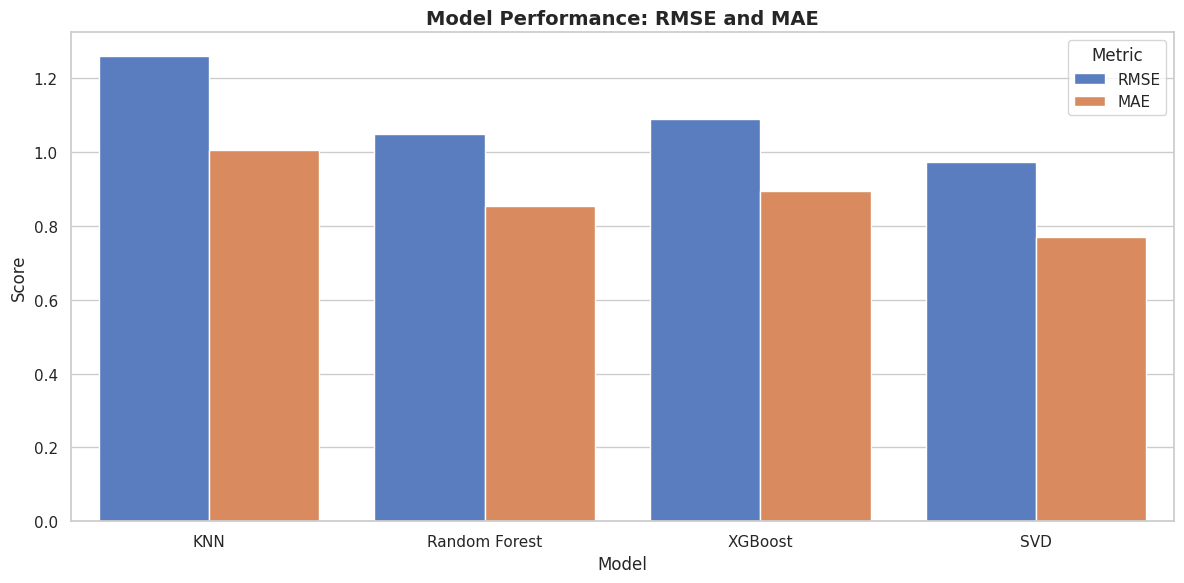


Bar plot saved as 'model_performance.png'.


In [ ]:
# Bar plot for RMSE and MAE
metrics = pd.DataFrame({
    'Model': ['KNN', 'Random Forest', 'XGBoost', 'SVD'],
    'RMSE': [knn_rmse, rf_rmse, xgb_rmse, svd_rmse],
    'MAE': [knn_mae, rf_mae, xgb_mae, svd_mae]
})
plt.figure(figsize=(12, 6))
metrics_melted = metrics.melt(id_vars='Model', value_vars=['RMSE', 'MAE'], var_name='Metric', value_name='Value')
sns.barplot(x='Model', y='Value', hue='Metric', data=metrics_melted)
plt.title('Model Performance: RMSE and MAE', fontsize=14, weight='bold')
plt.xlabel('Model', fontsize=12)
plt.ylabel('Score', fontsize=12)
plt.legend(title='Metric')
plt.tight_layout()
plt.savefig('model_performance.png')
plt.show()
print("\nBar plot saved as 'model_performance.png'.")

(0.0, 5.5)

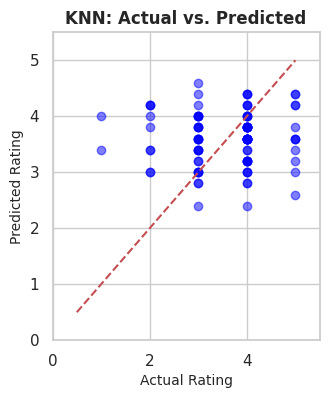

In [ ]:
plt.figure(figsize=(20, 4))
# KNN
plt.subplot(1, 5, 1)
plt.scatter(y_val[:100], knn_preds[:100], alpha=0.5, color='blue')
plt.plot([0.5, 5], [0.5, 5], 'r--')
plt.title('KNN: Actual vs. Predicted', fontsize=12, weight='bold')
plt.xlabel('Actual Rating', fontsize=10)
plt.ylabel('Predicted Rating', fontsize=10)
plt.xlim(0, 5.5)
plt.ylim(0, 5.5)

(0.0, 5.5)

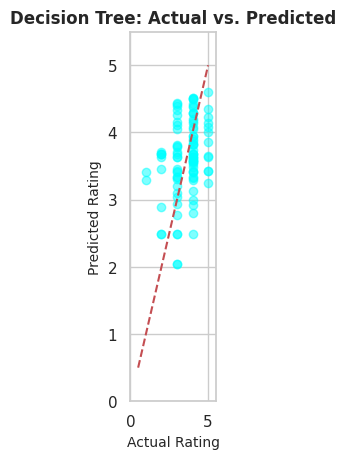

In [ ]:
plt.subplot(1, 5, 2)
plt.scatter(y_val[:100], dt_preds[:100], alpha=0.5, color='cyan')
plt.plot([0.5, 5], [0.5, 5], 'r--')
plt.title('Decision Tree: Actual vs. Predicted', fontsize=12, weight='bold')
plt.xlabel('Actual Rating', fontsize=10)
plt.ylabel('Predicted Rating', fontsize=10)
plt.xlim(0, 5.5)
plt.ylim(0, 5.5)

(0.0, 5.5)

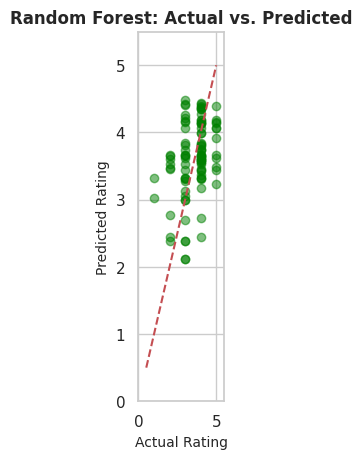

In [ ]:
# Random Forest
plt.subplot(1, 5, 3)
plt.scatter(y_val[:100], rf_preds[:100], alpha=0.5, color='green')
plt.plot([0.5, 5], [0.5, 5], 'r--')
plt.title('Random Forest: Actual vs. Predicted', fontsize=12, weight='bold')
plt.xlabel('Actual Rating', fontsize=10)
plt.ylabel('Predicted Rating', fontsize=10)
plt.xlim(0, 5.5)
plt.ylim(0, 5.5)

(0.0, 5.5)

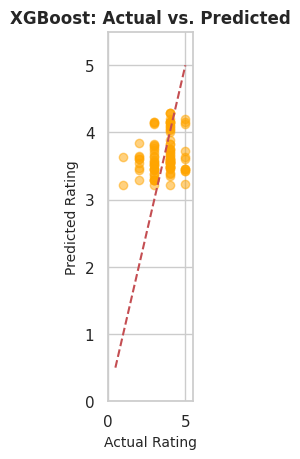

In [ ]:
plt.subplot(1, 5, 4)
plt.scatter(y_val[:100], xgb_preds[:100], alpha=0.5, color='orange')
plt.plot([0.5, 5], [0.5, 5], 'r--')
plt.title('XGBoost: Actual vs. Predicted', fontsize=12, weight='bold')
plt.xlabel('Actual Rating', fontsize=10)
plt.ylabel('Predicted Rating', fontsize=10)
plt.xlim(0, 5.5)
plt.ylim(0, 5.5)

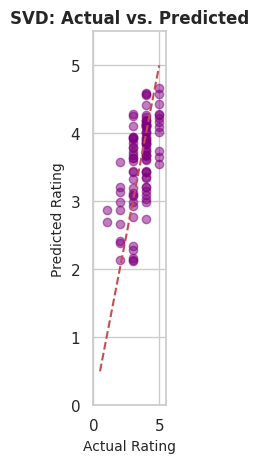


Scatter plot saved as 'actual_vs_predicted.png'.


In [ ]:
plt.subplot(1, 5, 5)
plt.scatter(val_ratings[:100], svd_preds[:100], alpha=0.5, color='purple')
plt.plot([0.5, 5], [0.5, 5], 'r--')
plt.title('SVD: Actual vs. Predicted', fontsize=12, weight='bold')
plt.xlabel('Actual Rating', fontsize=10)
plt.ylabel('Predicted Rating', fontsize=10)
plt.xlim(0, 5.5)
plt.ylim(0, 5.5)
plt.tight_layout()
plt.savefig('actual_vs_predicted.png')
plt.show()
print("\nScatter plot saved as 'actual_vs_predicted.png'.")

In [ ]:
pd.DataFrame({
    'UserID': validation_temporal['UserID'],
    'MovieID': validation_temporal['MovieID'],
    'Actual': y_val,
    'KNN_Pred': knn_preds,
    'DT_Pred': dt_preds,
    'RF_Pred': rf_preds,
    'XGB_Pred': xgb_preds
}).to_csv('predictions_supervised.csv', index=False)
print("\nSupervised predictions saved as 'predictions_supervised.csv'.")
print("\nAll models trained, evaluated, and visualized! Please share RMSE/MAE results to proceed!")


Supervised predictions saved as 'predictions_supervised.csv'.

All models trained, evaluated, and visualized! Please share RMSE/MAE results to proceed!



=== Validation Set ===
Validation set: 150031 rows

Validation set sample:
   UserID  MovieID  Rating
0    1209     3769       2
1    2664      150       4
2    1943     3596       1
3    3252     2987       3
4     563      405       1

=== 5.6 Visualizations: Showcasing Top Performers ===


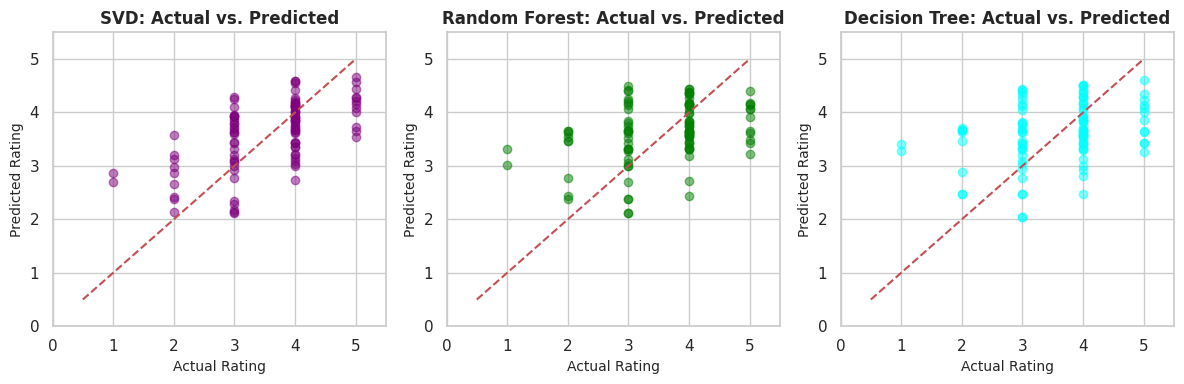


Scatter plot saved as 'top3_actual_vs_predicted.png'.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style='whitegrid')
sns.set_palette('muted')

try:
    validation = pd.read_csv('validation_data.csv')
except FileNotFoundError as e:
    print(f"Error: {e}")
    print("Please ensure 'validation_data.csv' is in your working directory.")
    raise

print("\n=== Validation Set ===")
print(f"Validation set: {len(validation)} rows")
print("\nValidation set sample:")
print(validation[['UserID', 'MovieID', 'Rating']].head())

#   Top 3 Models ===
print("\n=== 5.6 Visualizations: Showcasing Top Performers ===")

plt.figure(figsize=(12, 4))
# SVD
plt.subplot(1, 3, 1)
plt.scatter(val_ratings[:100], svd_preds[:100], alpha=0.5, color='purple')
plt.plot([0.5, 5], [0.5, 5], 'r--')
plt.title('SVD: Actual vs. Predicted', fontsize=12, weight='bold')
plt.xlabel('Actual Rating', fontsize=10)
plt.ylabel('Predicted Rating', fontsize=10)
plt.xlim(0, 5.5)
plt.ylim(0, 5.5)
# Random Forest
plt.subplot(1, 3, 2)
plt.scatter(y_val[:100], rf_preds[:100], alpha=0.5, color='green')
plt.plot([0.5, 5], [0.5, 5], 'r--')
plt.title('Random Forest: Actual vs. Predicted', fontsize=12, weight='bold')
plt.xlabel('Actual Rating', fontsize=10)
plt.ylabel('Predicted Rating', fontsize=10)
plt.xlim(0, 5.5)
plt.ylim(0, 5.5)
# Decision Tree
plt.subplot(1, 3, 3)
plt.scatter(y_val[:100], dt_preds[:100], alpha=0.5, color='cyan')
plt.plot([0.5, 5], [0.5, 5], 'r--')
plt.title('Decision Tree: Actual vs. Predicted', fontsize=12, weight='bold')
plt.xlabel('Actual Rating', fontsize=10)
plt.ylabel('Predicted Rating', fontsize=10)
plt.xlim(0, 5.5)
plt.ylim(0, 5.5)
plt.tight_layout()
plt.savefig('top3_actual_vs_predicted.png')
plt.show()
print("\nScatter plot saved as 'top3_actual_vs_predicted.png'.")

# Model Evaluation on Test Set

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error
from surprise import SVD, Dataset, Reader
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

In [ ]:
try:
    test_temporal = pd.read_csv('test_temporal_data.csv')
except FileNotFoundError as e:
    print(f"Error: {e}")
    print("Please ensure 'test_temporal_data.csv' is in your working directory.")
    raise

In [ ]:
print("\n=== Test Set ===")
print(f"Test set: {len(test_temporal)} rows")
print("\nTest set sample:")
print(test_temporal[['UserID', 'MovieID', 'Rating']].head())


=== Test Set ===
Test set: 150032 rows

Test set sample:
   UserID  MovieID  Rating
0     326     1263       2
1     326     1193       3
2     326      515       3
3    1917     1287       5
4     326     3471       4


In [ ]:
# Model Evaluation on Test Set
print("\n Model Evaluation: Testing Top Performers ===")

X_test = test_temporal[['UserID', 'MovieID']]
y_test = test_temporal['Rating']


 Model Evaluation: Testing Top Performers ===


In [ ]:
# Random Forest
rf = RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(train[['UserID', 'MovieID']], train['Rating'])
rf_test_preds = rf.predict(X_test)
rf_test_rmse = np.sqrt(mean_squared_error(y_test, rf_test_preds))
rf_test_mae = mean_absolute_error(y_test, rf_test_preds)
print("\nRandom Forest Test results:")
print(f"RMSE: {rf_test_rmse:.4f}")
print(f"MAE: {rf_test_mae:.4f}")
print("\nSample Random Forest Test predictions:")
print(pd.DataFrame({'Actual': y_test[:5].values, 'Predicted': rf_test_preds[:5]}))




Random Forest Test results:
RMSE: 1.0226
MAE: 0.8326

Sample Random Forest Test predictions:
   Actual  Predicted
0       2   4.109906
1       3   4.333119
2       3   3.430746
3       5   4.055083
4       4   3.574107


In [ ]:
# Decision Tree
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(max_depth=10, random_state=42)
dt.fit(train[['UserID', 'MovieID']], train['Rating'])
dt_test_preds = dt.predict(X_test)
dt_test_rmse = np.sqrt(mean_squared_error(y_test, dt_test_preds))
dt_test_mae = mean_absolute_error(y_test, dt_test_preds)
print("\nDecision Tree Test results:")
print(f"RMSE: {dt_test_rmse:.4f}")
print(f"MAE: {dt_test_mae:.4f}")
print("\nSample Decision Tree Test predictions:")
print(pd.DataFrame({'Actual': y_test[:5].values, 'Predicted': dt_test_preds[:5]}))




Decision Tree Test results:
RMSE: 1.0303
MAE: 0.8376

Sample Decision Tree Test predictions:
   Actual  Predicted
0       2   4.027100
1       3   4.382727
2       3   3.416241
3       5   4.059980
4       4   3.565709


In [ ]:
# SVD
reader = Reader(rating_scale=(0.5, 5.0))
trainset_data = train[['UserID', 'MovieID', 'Rating']]
testset_data = test_temporal[['UserID', 'MovieID', 'Rating']]
trainset = Dataset.load_from_df(trainset_data, reader).build_full_trainset()
testset = [(uid, iid, r) for uid, iid, r in testset_data.itertuples(index=False)]
svd = SVD(n_factors=100, n_epochs=20, random_state=42)
svd.fit(trainset)
svd_test_preds = [svd.predict(uid, iid, r).est for uid, iid, r in testset]
test_ratings = [r for _, _, r in testset]
svd_test_rmse = np.sqrt(mean_squared_error(test_ratings, svd_test_preds))
svd_test_mae = mean_absolute_error(test_ratings, svd_test_preds)
print("\nSVD Test results:")
print(f"RMSE: {svd_test_rmse:.4f}")
print(f"MAE: {svd_test_mae:.4f}")
print("\nSample SVD Test predictions:")
print(pd.DataFrame({'Actual': test_ratings[:5], 'Predicted': svd_test_preds[:5]}))




SVD Test results:
RMSE: 0.7333
MAE: 0.5726

Sample SVD Test predictions:
   Actual  Predicted
0       2   3.029810
1       3   3.550966
2       3   3.194660
3       5   4.313497
4       4   3.593705


In [ ]:
# Save test predictions
pd.DataFrame({
    'UserID': test_temporal['UserID'],
    'MovieID': test_temporal['MovieID'],
    'Actual': y_test,
    'RF_Pred': rf_test_preds,
    'DT_Pred': dt_test_preds
}).to_csv('test_predictions_supervised.csv', index=False)
pd.DataFrame({
    'UserID': test_temporal['UserID'],
    'MovieID': test_temporal['MovieID'],
    'Actual': test_ratings,
    'SVD_Pred': svd_test_preds
}).to_csv('test_predictions_svd.csv', index=False)
print("\nTest predictions saved as 'test_predictions_supervised.csv' and 'test_predictions_svd.csv'.")
print("\nAll top models evaluated on test set! Ready for the next step!")


Test predictions saved as 'test_predictions_supervised.csv' and 'test_predictions_svd.csv'.

All top models evaluated on test set! Ready for the next step!


# Model Tuning: Optimizing SVD for Precision

In [ ]:
import pandas as pd
import numpy as np
from surprise import SVD, Dataset, Reader
from surprise.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [ ]:
try:
    train = pd.read_csv('train_data.csv')
    validation = pd.read_csv('validation_data.csv')
except FileNotFoundError as e:
    print(f"Error: {e}")
    print("Please ensure 'train_data.csv' and 'validation_data.csv' are in your working directory.")
    raise

In [ ]:
print("\n=== Dataset Sizes ===")
print(f"Train set: {len(train)} rows")
print(f"Validation set: {len(validation)} rows")
print("\nTrain set sample:")
print(train[['UserID', 'MovieID', 'Rating']].head())
print("\nValidation set sample:")
print(validation[['UserID', 'MovieID', 'Rating']].head())


=== Dataset Sizes ===
Train set: 700146 rows
Validation set: 150031 rows

Train set sample:
   UserID  MovieID  Rating
0    3314     2787       2
1      48      647       3
2    3770     1079       4
3     524     1126       1
4    3434     2470       3

Validation set sample:
   UserID  MovieID  Rating
0    1209     3769       2
1    2664      150       4
2    1943     3596       1
3    3252     2987       3
4     563      405       1


In [ ]:
reader = Reader(rating_scale=(0.5, 5.0))
data = Dataset.load_from_df(train[['UserID', 'MovieID', 'Rating']], reader)

In [ ]:
param_grid = {
    'n_factors': [50, 100, 150],
    'n_epochs': [10, 20, 30],
    'lr_all': [0.005, 0.01],
    'reg_all': [0.02, 0.1]
}

print("\n  Grid Search for SVD ===")
gs = GridSearchCV(SVD, param_grid, measures=['rmse', 'mae'], cv=3, n_jobs=-1)
gs.fit(data)


  Grid Search for SVD ===


In [ ]:
best_rmse = gs.best_score['rmse']
best_mae = gs.best_score['mae']
best_params = gs.best_params['rmse']
print("\nBest SVD Parameters:")
print(f"Parameters: {best_params}")
print(f"Best RMSE: {best_rmse:.4f}")
print(f"Best MAE: {best_mae:.4f}")


Best SVD Parameters:
Parameters: {'n_factors': 150, 'n_epochs': 30, 'lr_all': 0.01, 'reg_all': 0.1}
Best RMSE: 0.8830
Best MAE: 0.6994


In [ ]:
print("\n Training SVD with Best Parameters ")
svd = SVD(n_factors=best_params['n_factors'], n_epochs=best_params['n_epochs'],
          lr_all=best_params['lr_all'], reg_all=best_params['reg_all'], random_state=42)
trainset = data.build_full_trainset()
svd.fit(trainset)


 Training SVD with Best Parameters 


In [ ]:
valset_data = validation[['UserID', 'MovieID', 'Rating']]
valset = [(uid, iid, r) for uid, iid, r in valset_data.itertuples(index=False)]
svd_preds = [svd.predict(uid, iid, r).est for uid, iid, r in valset]
val_ratings = [r for _, _, r in valset]
svd_rmse = np.sqrt(mean_squared_error(val_ratings, svd_preds))
svd_mae = mean_absolute_error(val_ratings, svd_preds)
print("\nTuned SVD Validation results:")
print(f"RMSE: {svd_rmse:.4f}")
print(f"MAE: {svd_mae:.4f}")
print("\nSample Tuned SVD predictions:")
print(pd.DataFrame({'Actual': val_ratings[:5], 'Predicted': svd_preds[:5]}))


Tuned SVD Validation results:
RMSE: 0.8764
MAE: 0.6961

Sample Tuned SVD predictions:
   Actual  Predicted
0       2   3.217238
1       4   4.159106
2       1   2.531458
3       3   3.213898
4       1   1.336215


In [ ]:
pd.DataFrame({
    'UserID': validation['UserID'],
    'MovieID': validation['MovieID'],
    'Actual': val_ratings,
    'SVD_Pred': svd_preds
}).to_csv('tuned_svd_predictions.csv', index=False)
print("\nTuned SVD predictions saved as 'tuned_svd_predictions.csv'.")
print("\nSVD tuning complete")


Tuned SVD predictions saved as 'tuned_svd_predictions.csv'.

SVD tuning complete


# Test Set and Validation set IN one

In [ ]:
import pandas as pd
import numpy as np
from surprise import SVD, Dataset, Reader
from sklearn.metrics import mean_squared_error, mean_absolute_error

print("\n Model Evaluation: Re-checking Tuned SVD on Test Set ===")

try:
    train = pd.read_csv('train_data.csv')
    test_temporal = pd.read_csv('test_temporal_data.csv')
except FileNotFoundError as e:
    print(f"Error: {e}")
    print("Please ensure 'train_data.csv' and 'test_temporal_data.csv' are in the current directory.")
    raise

print("\n Dataset Sizes ")
print(f"Train set: {len(train)} rows")
print(f"Test set: {len(test_temporal)} rows")
print("\nTrain set sample:")
print(train[['UserID', 'MovieID', 'Rating']].head())
print("\nTest set sample:")
print(test_temporal[['UserID', 'MovieID', 'Rating']].head())

reader = Reader(rating_scale=(0.5, 5.0))
trainset_data = train[['UserID', 'MovieID', 'Rating']]
testset_data = test_temporal[['UserID', 'MovieID', 'Rating']]
trainset = Dataset.load_from_df(trainset_data, reader).build_full_trainset()
testset = [(uid, iid, r) for uid, iid, r in testset_data.itertuples(index=False)]

print("\nTraining SVD with Tuned Parameters ")
svd = SVD(n_factors=150, n_epochs=30, lr_all=0.01, reg_all=0.1, random_state=42)
svd.fit(trainset)

print("\n Re-evaluating SVD on Test Set ===")
svd_test_preds = [svd.predict(uid, iid, r).est for uid, iid, r in testset]
test_ratings = [r for _, _, r in testset]
svd_test_rmse = np.sqrt(mean_squared_error(test_ratings, svd_test_preds))
svd_test_mae = mean_absolute_error(test_ratings, svd_test_preds)
print("\nRe-checked Tuned SVD Test Results:")
print(f"RMSE: {svd_test_rmse:.4f}")
print(f"MAE: {svd_test_mae:.4f}")
print("\nRe-checked Tuned SVD Test Prediction Samples:")
print(pd.DataFrame({'Actual': test_ratings[:5], 'Predicted': svd_test_preds[:5]}))



 Model Evaluation: Re-checking Tuned SVD on Test Set ===

 Dataset Sizes 
Train set: 700146 rows
Test set: 150032 rows

Train set sample:
   UserID  MovieID  Rating
0    3314     2787       2
1      48      647       3
2    3770     1079       4
3     524     1126       1
4    3434     2470       3

Test set sample:
   UserID  MovieID  Rating
0     326     1263       2
1     326     1193       3
2     326      515       3
3    1917     1287       5
4     326     3471       4

Training SVD with Tuned Parameters 

 Re-evaluating SVD on Test Set ===

Re-checked Tuned SVD Test Results:
RMSE: 0.8278
MAE: 0.6549

Re-checked Tuned SVD Test Prediction Samples:
   Actual  Predicted
0       2   3.452957
1       3   3.540068
2       3   3.226957
3       5   4.344334
4       4   3.405061


In [ ]:

pd.DataFrame({
    'UserID': test_temporal['UserID'],
    'MovieID': test_temporal['MovieID'],
    'Actual': test_ratings,
    'SVD_Predicted': svd_test_preds
}).to_csv('test_tuned_svd_predictions_recheck.csv', index=False)
print("\nTest predictions saved as 'test_tuned_svd_predictions_recheck.csv'.")
print("\nSVD test evaluation re-checked! Ready for the next step!")


Test predictions saved as 'test_tuned_svd_predictions_recheck.csv'.

SVD test evaluation re-checked! Ready for the next step!


# Error Analysis va Static Recommendations

In [ ]:
import pandas as pd
import numpy as np
from surprise import SVD, Dataset, Reader


try:
    train = pd.read_csv('train_data.csv')
    test_predictions = pd.read_csv('test_tuned_svd_predictions_recheck.csv')
except FileNotFoundError as e:
    print(f"Error: {e}")
    print("Please ensure 'train_data.csv' and 'test_tuned_svd_predictions_recheck.csv' are in the current directory.")
    raise

In [ ]:
print(f"Train set: {len(train)} rows")
print(f"Test predictions: {len(test_predictions)} rows")
print("\nTest predictions sample:")
print(test_predictions[['UserID', 'MovieID', 'Actual', 'SVD_Predicted']].head())

Train set: 700146 rows
Test predictions: 150032 rows

Test predictions sample:
   UserID  MovieID  Actual  SVD_Predicted
0     326     1263       2       3.452957
1     326     1193       3       3.540068
2     326      515       3       3.226957
3    1917     1287       5       4.344334
4     326     3471       4       3.405061


In [ ]:
# Calculate prediction errors
test_predictions['Error'] = test_predictions['Actual'] - test_predictions['SVD_Predicted']
test_predictions['Abs_Error'] = test_predictions['Error'].abs()

In [ ]:
user_error_stats = test_predictions.groupby('UserID').agg({
    'Abs_Error': ['mean', 'count'],
    'Error': ['mean']
}).reset_index()
user_error_stats.columns = ['UserID', 'Mean_Abs_Error', 'Prediction_Count', 'Mean_Error']
print("\nUser-based error statistics (first 5):")
print(user_error_stats.head())


User-based error statistics (first 5):
   UserID  Mean_Abs_Error  Prediction_Count  Mean_Error
0       1        0.538478                53    0.081233
1       2        0.667735               129   -0.064700
2       3        0.691021                51    0.116601
3       4        0.664164                21    0.087746
4       5        0.778056               198    0.032065


In [ ]:
# Users with highest errors
top_error_users = user_error_stats.sort_values('Mean_Abs_Error', ascending=False).head(5)
print("\nUsers with highest prediction errors:")
print(top_error_users)


Users with highest prediction errors:
      UserID  Mean_Abs_Error  Prediction_Count  Mean_Error
742     1862        2.901403                 1   -2.901403
1300    4738        2.634137                 1    2.634137
1380    5202        2.035810                 1   -2.035810
452      768        1.971974                 1   -1.971974
898     2535        1.849243                 1    1.849243


In [ ]:
# Movie-based error analysis
movie_error_stats = test_predictions.groupby('MovieID').agg({
    'Abs_Error': ['mean', 'count'],
    'Error': ['mean']
}).reset_index()
movie_error_stats.columns = ['MovieID', 'Mean_Abs_Error', 'Prediction_Count', 'Mean_Error']
print("\nMovie-based error statistics (first 5):")
print(movie_error_stats.head())


Movie-based error statistics (first 5):
   MovieID  Mean_Abs_Error  Prediction_Count  Mean_Error
0        1        0.590548               221    0.043829
1        2        0.673898               103    0.118136
2        3        0.702418                56   -0.140764
3        4        0.601460                26   -0.017550
4        5        0.709894                45    0.083330


In [ ]:
# Movies with highest errors
top_error_movies = movie_error_stats.sort_values('Mean_Abs_Error', ascending=False).head(5)
print("\nMovies with highest prediction errors:")
print(top_error_movies)


Movies with highest prediction errors:
      MovieID  Mean_Abs_Error  Prediction_Count  Mean_Error
955      1102        3.182872                 1   -3.182872
2835     3228        2.662117                 1   -2.662117
3201     3651        2.196163                 1   -2.196163
1856     2158        2.187635                 1    2.187635
736       847        2.149621                 1   -2.149621


In [ ]:
user_error_stats.to_csv('user_error_stats.csv', index=False)
movie_error_stats.to_csv('movie_error_stats.csv', index=False)
print("\nError analysis saved as 'user_error_stats.csv' and 'movie_error_stats.csv'.")


Error analysis saved as 'user_error_stats.csv' and 'movie_error_stats.csv'.


# Static Recommendations: Top-5 Movies

In [ ]:
reader = Reader(rating_scale=(0.5, 5.0))
trainset_data = train[['UserID', 'MovieID', 'Rating']]
trainset = Dataset.load_from_df(trainset_data, reader).build_full_trainset()
svd = SVD(n_factors=150, n_epochs=30, lr_all=0.01, reg_all=0.1, random_state=42)
svd.fit(trainset)

In [ ]:
random_user = test_predictions['UserID'].sample(1).iloc[0]
print(f"\nRandom user: UserID {random_user}")


Random user: UserID 2918


In [ ]:
# Identify movies not rated by the user
user_rated_movies = train[train['UserID'] == random_user]['MovieID'].unique()
all_movies = train['MovieID'].unique()
unrated_movies = [movie for movie in all_movies if movie not in user_rated_movies]

 Generate top-5 recommendations




In [ ]:

predictions = [(movie, svd.predict(random_user, movie).est) for movie in unrated_movies]
predictions.sort(key=lambda x: x[1], reverse=True)
top_5_recommendations = predictions[:5]

In [ ]:
print(f"\nTop-5 recommendations for UserID {random_user}:")
for i, (movie_id, rating) in enumerate(top_5_recommendations, 1):
    print(f"{i}. MovieID {movie_id}, Predicted Rating: {rating:.2f}")


Top-5 recommendations for UserID 2918:
1. MovieID 2019, Predicted Rating: 4.72
2. MovieID 3134, Predicted Rating: 4.71
3. MovieID 923, Predicted Rating: 4.68
4. MovieID 2905, Predicted Rating: 4.65
5. MovieID 2731, Predicted Rating: 4.65


In [ ]:
recommendations_df = pd.DataFrame({
    'UserID': [random_user] * 5,
    'MovieID': [movie_id for movie_id, _ in top_5_recommendations],
    'Predicted_Rating': [rating for _, rating in top_5_recommendations]
})
recommendations_df.to_csv('top_5_recommendations.csv', index=False)


# Reinforcement Learning

In [ ]:
import pandas as pd
import numpy as np
from surprise import SVD, Dataset, Reader
import random

print("\n=== Phase 2, Step 1: Reinforcement Learning Environment Setup ===")


try:
    train = pd.read_csv('train_data.csv')
    recommendations = pd.read_csv('top_5_recommendations.csv')
except FileNotFoundError as e:
    print(f"Error: {e}")
    print("Please ensure 'train_data.csv' and 'top_5_recommendations.csv' are in the current directory.")
    raise


print("\n=== Dataset Sizes ===")
print(f"Train set: {len(train)} rows")
print(f"Recommendations: {len(recommendations)} rows")
print("\nTrain set sample:")
print(train[['UserID', 'MovieID', 'Rating']].head())
print("\nRecommendations sample:")
print(recommendations.head())


=== Phase 2, Step 1: Reinforcement Learning Environment Setup ===

=== Dataset Sizes ===
Train set: 700146 rows
Recommendations: 5 rows

Train set sample:
   UserID  MovieID  Rating
0    3314     2787       2
1      48      647       3
2    3770     1079       4
3     524     1126       1
4    3434     2470       3

Recommendations sample:
   UserID  MovieID  Predicted_Rating
0    2918     2019          4.724173
1    2918     3134          4.713494
2    2918      923          4.678848
3    2918     2905          4.654345
4    2918     2731          4.648753


In [ ]:
class RecommendationEnv:
    def __init__(self, train_data, svd_model, user_id, all_movies):
        self.train_data = train_data
        self.svd_model = svd_model
        self.user_id = user_id
        self.all_movies = all_movies
        self.rated_movies = set(train_data[train_data['UserID'] == user_id]['MovieID'].unique())
        self.state = self.get_initial_state()
        self.available_actions = [m for m in all_movies if m not in self.rated_movies]

    def get_initial_state(self):
        user_ratings = self.train_data[self.train_data['UserID'] == self.user_id]['Rating']
        avg_rating = user_ratings.mean() if len(user_ratings) > 0 else 3.0
        num_rated = len(user_ratings)
        return {'avg_rating': avg_rating, 'num_rated': num_rated}

    def step(self, action):

        predicted_rating = self.svd_model.predict(self.user_id, action).est
        if predicted_rating >= 4:
            reward = 1
        elif predicted_rating < 3:
            reward = -1
        else:
            reward = 0

        self.rated_movies.add(action)
        self.available_actions = [m for m in self.available_actions if m != action]
        self.state = self.get_initial_state()

        done = len(self.available_actions) == 0
        return self.state, reward, done

    def reset(self):

        self.rated_movies = set(self.train_data[self.train_data['UserID'] == self.user_id]['MovieID'].unique())
        self.available_actions = [m for m in self.all_movies if m not in self.rated_movies]
        self.state = self.get_initial_state()
        return self.state

In [ ]:
print("\n=== Loading SVD Model for Initial Policy ===")
reader = Reader(rating_scale=(0.5, 5.0))
trainset_data = train[['UserID', 'MovieID', 'Rating']]
trainset = Dataset.load_from_df(trainset_data, reader).build_full_trainset()
svd = SVD(n_factors=150, n_epochs=30, lr_all=0.01, reg_all=0.1, random_state=42)
svd.fit(trainset)

# Initialize environment
print("\n=== Initializing RL Environment ===")
random_user = recommendations['UserID'].iloc[0]  # Use user from recommendations
all_movies = train['MovieID'].unique()
env = RecommendationEnv(train, svd, random_user, all_movies)



=== Loading SVD Model for Initial Policy ===

=== Initializing RL Environment ===


In [ ]:
print(f"\nTesting RL Environment for UserID {random_user}")
state = env.reset()
print(f"Initial state: {state}")
action = random.choice(env.available_actions)
next_state, reward, done = env.step(action)
print(f"Action (MovieID): {action}")
print(f"Next state: {next_state}")
print(f"Reward: {reward}")
print(f"Done: {done}")


Testing RL Environment for UserID 2918
Initial state: {'avg_rating': 3.5481481481481483, 'num_rated': 270}
Action (MovieID): 1777
Next state: {'avg_rating': 3.5481481481481483, 'num_rated': 270}
Reward: 0
Done: False


In [ ]:
# Reward 0 bo‘lishi taxminiy baho 3–4

In [ ]:
env_details = pd.DataFrame({
    'UserID': [random_user],
    'Num_Available_Movies': [len(env.available_actions)],
    'Initial_Avg_Rating': [state['avg_rating']],
    'Initial_Num_Rated': [state['num_rated']]
})
env_details.to_csv('rl_environment_setup.csv', index=False)
print("\nRL environment saved  'rl_environment_setup.csv'.")


RL environment saved  'rl_environment_setup.csv'.


# Q-Learning Implementation

In [ ]:
import pandas as pd
import numpy as np
from surprise import SVD, Dataset, Reader
import random

try:
    train = pd.read_csv('train_data.csv')
except FileNotFoundError as e:
    print(f"Error: {e}")
    print("Please ensure 'train_data.csv' is in the current directory.")
    raise

print("\n=== Dataset Size ===")
print(f"Train set: {len(train)} rows")
print("\nTrain set sample:")
print(train[['UserID', 'MovieID', 'Rating']].head())


=== Dataset Size ===
Train set: 700146 rows

Train set sample:
   UserID  MovieID  Rating
0    3314     2787       2
1      48      647       3
2    3770     1079       4
3     524     1126       1
4    3434     2470       3


In [ ]:
class RecommendationEnv:
    def __init__(self, train_data, svd_model, user_id, all_movies):
        self.train_data = train_data
        self.svd_model = svd_model
        self.user_id = user_id
        self.all_movies = all_movies
        self.rated_movies = set(train_data[train_data['UserID'] == user_id]['MovieID'].unique())
        self.state = self.get_initial_state()
        self.available_actions = [m for m in all_movies if m not in self.rated_movies]

    def get_initial_state(self):
        user_ratings = self.train_data[self.train_data['UserID'] == self.user_id]['Rating']
        avg_rating = user_ratings.mean() if len(user_ratings) > 0 else 3.0
        num_rated = len(user_ratings)
        return {'avg_rating': round(avg_rating, 1), 'num_rated': num_rated // 100}  # Simplified state

    def step(self, action):
        predicted_rating = self.svd_model.predict(self.user_id, action).est
        if predicted_rating >= 4:
            reward = 1
        elif predicted_rating < 3:
            reward = -1
        else:
            reward = 0
        self.rated_movies.add(action)
        self.available_actions = [m for m in self.available_actions if m != action]
        self.state = self.get_initial_state()
        done = len(self.available_actions) == 0
        return self.state, reward, done

    def reset(self):
        self.rated_movies = set(self.train_data[self.train_data['UserID'] == self.user_id]['MovieID'].unique())
        self.available_actions = [m for m in self.all_movies if m not in self.rated_movies]
        self.state = self.get_initial_state()
        return self.state

In [ ]:
print("\n=== Loading SVD Model for Initial Policy ===")
reader = Reader(rating_scale=(0.5, 5.0))
trainset_data = train[['UserID', 'MovieID', 'Rating']]
trainset = Dataset.load_from_df(trainset_data, reader).build_full_trainset()
svd = SVD(n_factors=150, n_epochs=30, lr_all=0.01, reg_all=0.1, random_state=42)
svd.fit(trainset)

# Initialize environment
user_id = 4305  # From previous recommendations
all_movies = train['MovieID'].unique()
env = RecommendationEnv(train, svd, user_id, all_movies)


=== Loading SVD Model for Initial Policy ===


# Q-Learning implementation

In [ ]:
q_table = {}
alpha = 0.1
gamma = 0.9
epsilon = 0.1

def get_q_value(state, action):
    state_key = (state['avg_rating'], state['num_rated'])
    return q_table.get((state_key, action), 0.0)

def set_q_value(state, action, value):
    state_key = (state['avg_rating'], state['num_rated'])
    q_table[(state_key, action)] = value

def choose_action(state, available_actions):
    if random.random() < epsilon:
        return random.choice(available_actions)
    else:
        q_values = [get_q_value(state, a) for a in available_actions]
        max_q = max(q_values) if q_values else 0
        max_actions = [a for a, q in zip(available_actions, q_values) if q == max_q]
        return random.choice(max_actions if max_actions else available_actions)  # E

In [ ]:
episodes = 200
total_rewards = []
print(f"\nTraining Q-Learning for {episodes} episodes...")
for episode in range(episodes):
    state = env.reset()
    episode_reward = 0
    done = False
    while not done:
        action = choose_action(state, env.available_actions)
        next_state, reward, done = env.step(action)
        episode_reward += reward

        current_q = get_q_value(state, action)
        next_q_values = [get_q_value(next_state, a) for a in env.available_actions]
        max_next_q = max(next_q_values) if next_q_values else 0
        new_q = current_q + alpha * (reward + gamma * max_next_q - current_q)
        set_q_value(state, action, new_q)
        state = next_state
    total_rewards.append(episode_reward)
    if (episode + 1) % 10 == 0:
        print(f"Episode {episode + 1}, Total Reward: {episode_reward}")


Training Q-Learning for 200 episodes...
Episode 10, Total Reward: 507
Episode 20, Total Reward: 507
Episode 30, Total Reward: 507
Episode 40, Total Reward: 507
Episode 50, Total Reward: 507
Episode 60, Total Reward: 507
Episode 70, Total Reward: 507
Episode 80, Total Reward: 507
Episode 90, Total Reward: 507
Episode 100, Total Reward: 507
Episode 110, Total Reward: 507
Episode 120, Total Reward: 507
Episode 130, Total Reward: 507
Episode 140, Total Reward: 507
Episode 150, Total Reward: 507
Episode 160, Total Reward: 507
Episode 170, Total Reward: 507
Episode 180, Total Reward: 507
Episode 190, Total Reward: 507
Episode 200, Total Reward: 507


In [ ]:
q_learning_results = pd.DataFrame({
    'Episode': range(1, episodes + 1),
    'Total_Reward': total_rewards
})
q_learning_results.to_csv('q_learning_results.csv', index=False)
print("\nQ-Learning results saved as 'q_learning_results.csv'.")


Q-Learning results saved as 'q_learning_results.csv'.


In [ ]:

print(f"\nTesting learned Q-Learning policy for UserID {user_id}")
state = env.reset()
recommended_movies = []
for _ in range(5):  #5 ta tavsiyaga
    action = choose_action(state, env.available_actions)
    predicted_rating = svd.predict(user_id, action).est
    recommended_movies.append((action, predicted_rating))
    next_state, _, done = env.step(action)
    state = next_state
    if done:
        break

print(f"\nTop-5 recommendations after Q-Learning for UserID {user_id}:")
for i, (movie_id, rating) in enumerate(recommended_movies, 1):
    print(f"{i}. MovieID {movie_id}, Predicted Rating: {rating:.2f}")


Testing learned Q-Learning policy for UserID 4305

Top-5 recommendations after Q-Learning for UserID 4305:
1. MovieID 649, Predicted Rating: 4.58
2. MovieID 1089, Predicted Rating: 4.10
3. MovieID 2330, Predicted Rating: 4.20
4. MovieID 3255, Predicted Rating: 4.03
5. MovieID 746, Predicted Rating: 4.35


In [ ]:
recommendations_df = pd.DataFrame({
    'UserID': [user_id] * len(recommended_movies),
    'MovieID': [movie_id for movie_id, _ in recommended_movies],
    'Predicted_Rating': [rating for _, rating in recommended_movies]
})
recommendations_df.to_csv('q_learning_recommendations.csv', index=False)